In [1]:
import scanpy as sc
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

from utils.io import read_anndata

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_elem from `anndata.experimental` is deprecated. Import anndata.io.read_elem instead.
  warnings.warn(msg, FutureWarning)
/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing sparse_dataset from `anndata.experimental` is deprecated. Import anndata.io.sparse_dataset instead.
  warnings.warn(msg, FutureWarning)


# Read Data

In [2]:
adata = read_anndata(
    'data/pipeline/hlca/label_transfer/dataset~Immune/file_id~collect:Immune.zarr/',
    obs='obs',
    obsm='obsm',
    uns='uns',
    obsp='obsp',
    dask_slots=['layers', 'X', 'obsp'],
    dask=True,
    backed=True,
)

FileNotFoundError: Cannot read file data/pipeline/hlca/label_transfer/dataset~Immune/file_id~collect:Immune.zarr/

In [3]:
adata.obsp = {
    key.replace('metrics:', ''): value for key, value in adata.obsp.items()
}
adata.obsm = {
    key.replace('metrics:', ''): value for key, value in adata.obsm.items()
}

In [4]:
adata.obs.columns = [col.replace('metrics:', '') for col in adata.obs.columns]

In [5]:
adata.obs.columns

Index(['suspension_type', 'donor_id', 'is_primary_data',
       'assay_ontology_term_id', 'cell_type_ontology_term_id',
       'development_stage_ontology_term_id', 'disease_ontology_term_id',
       'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id',
       'sex_ontology_term_id',
       ...
       'leiden_1.0_2--integration=837ca7f62a--strategy=lineage',
       'leiden_1.0_3--integration=837ca7f62a--strategy=lineage',
       'majority_reference--integration=837ca7f62a--strategy=lineage',
       'leiden_1.0_1--integration=837ca7f62a--strategy=global',
       'leiden_1.0_2--integration=837ca7f62a--strategy=global',
       'leiden_1.0_3--integration=837ca7f62a--strategy=global',
       'majority_reference--integration=837ca7f62a--strategy=global',
       'majority_consensus', 'majority_consensus_agreement',
       'majority_consensus_low_agreement'],
      dtype='object', length=131)

In [6]:
integrations = list({col.split('--')[1].split(':')[-1] for col in adata.obs.columns if '--' in col})
integrations

['integration=24ff6a6128',
 'integration=837ca7f62a',
 'integration=08c6548170',
 'integration=2062d25075',
 'integration=f4e267c962']

In [7]:
adata.obs['majority_consensus'] = adata.obs['majority_consensus'].cat.set_categories(adata.obs['ann_finest_level'].cat.categories)

In [8]:
annotation_colors = [
    'ann_finest_level',
    # 'ann_level_2',
    # 'ann_level_3',
    # 'ann_level_4',
    # 'ann_level_5',
    'majority_consensus',
]
batch_colors = [
    'dataset',
    # 'study',
    'assay',
    # 'fresh_or_frozen',
    # 'tissue_dissociation_protocol',
    'tissue_sampling_method',
]
covariates = [
    'BMI',
    'age_or_mean_of_age_range',
    'age_range',
    'anatomical_region_ccf_score',
    'lung_condition',
    'reannotation_type',
    'smoking_status',
    # 'cause_of_death',
    # 'subject_type',
    'tissue_level_2',
    'tissue_level_3',
    'sex',
    'tissue',
    'scrublet_score',
]

In [9]:
df = pd.read_table('data/pipeline/hlca/clustering/input_files.tsv')

df['integration_id'] = df['file_id'].str.split('--').str[1]
df[['method', 'hyperparams', 'label', 'output_type']] = df['file_path'].str.split('method~').str[1].str.split('--', expand=True)
df['var_mask'] = df['file_path'].str.split('var_mask~').str[1].str.split('/').str[0]

df = df[['integration_id', 'var_mask', 'method', 'hyperparams']].dropna().drop_duplicates()

In [10]:
df.query(f'integration_id.isin(@integrations)')

,integration_id,var_mask,method,hyperparams
48,integration=24ff6a6128,extra_hvgs--batch_key=dataset--n_top_genes=2000,unintegrated,hyperparams~None
49,integration=f4e267c962,extra_hvgs--batch_key=dataset--n_top_genes=2000,harmony_pytorch,hyperparams~c606b8bfe0
50,integration=2062d25075,extra_hvgs--batch_key=dataset--n_top_genes=2000,scvi,hyperparams~f4b391733b
52,integration=837ca7f62a,extra_hvgs--batch_key=dataset--n_top_genes=2000,drvi,hyperparams~4a9ca95bc9
53,integration=08c6548170,extra_hvgs--batch_key=dataset--n_top_genes=2000,scpoli,hyperparams~d8f7bfa1e2


# UMAPs

## scANVI reference

## scVI

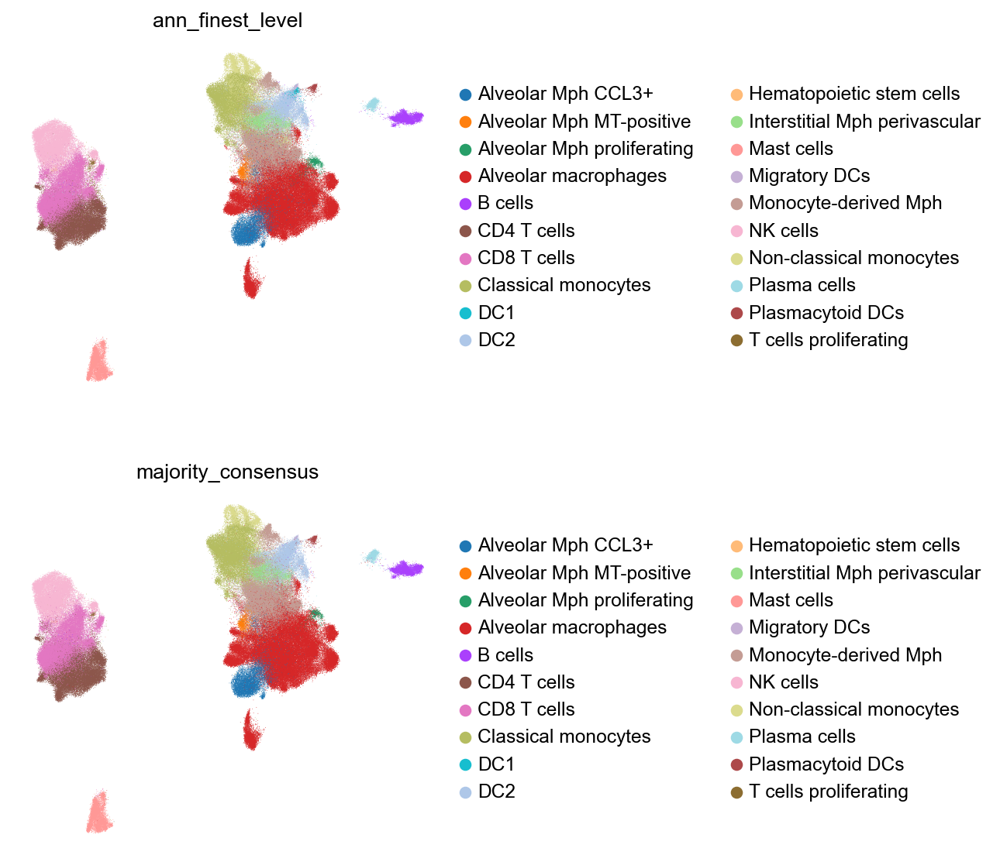

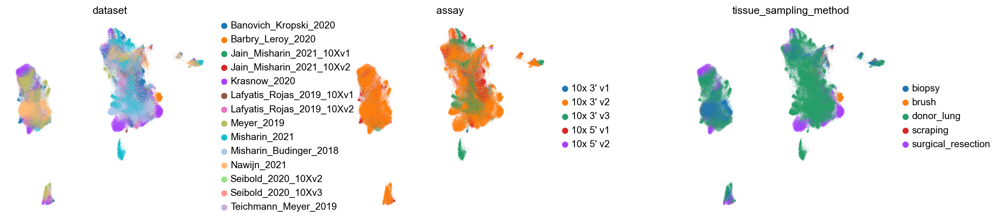

In [11]:
integration = '2062d25075'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors,
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

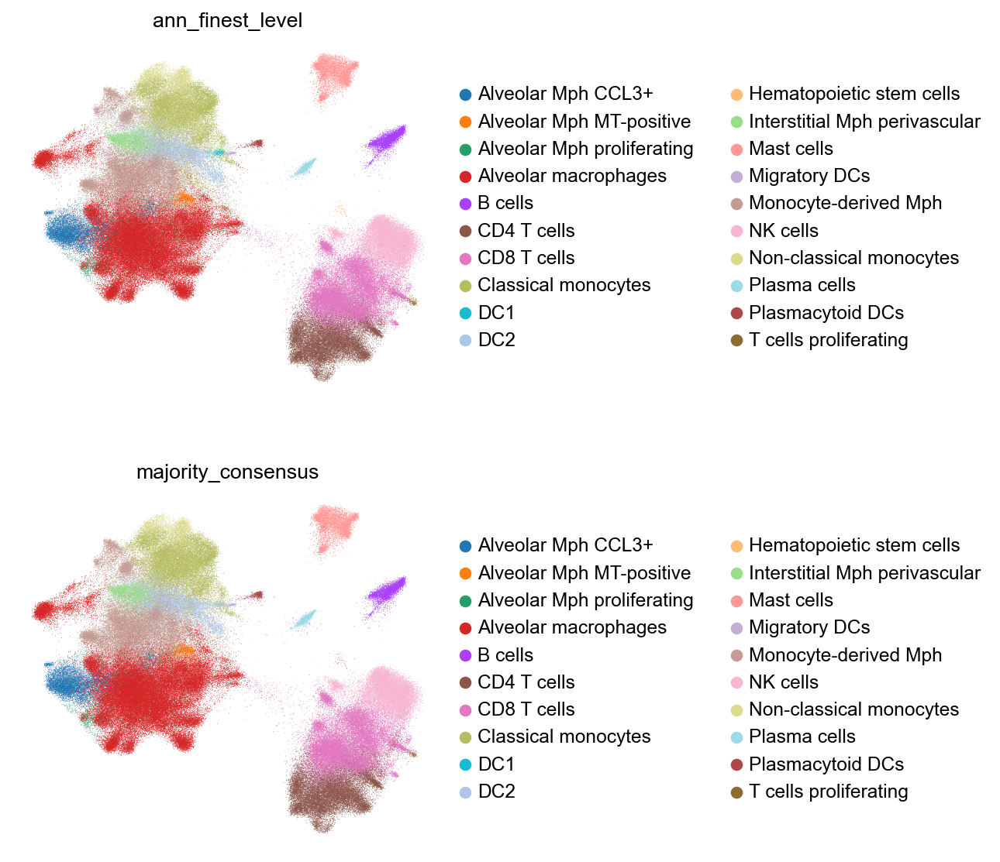

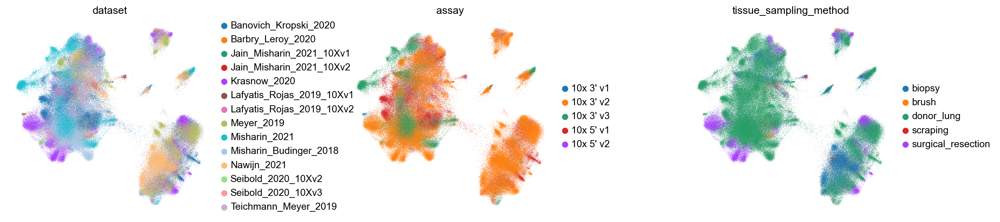

In [12]:
integration = '2062d25075'
strategy = 'lineage'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors, 
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

## Harmony
With scaled counts

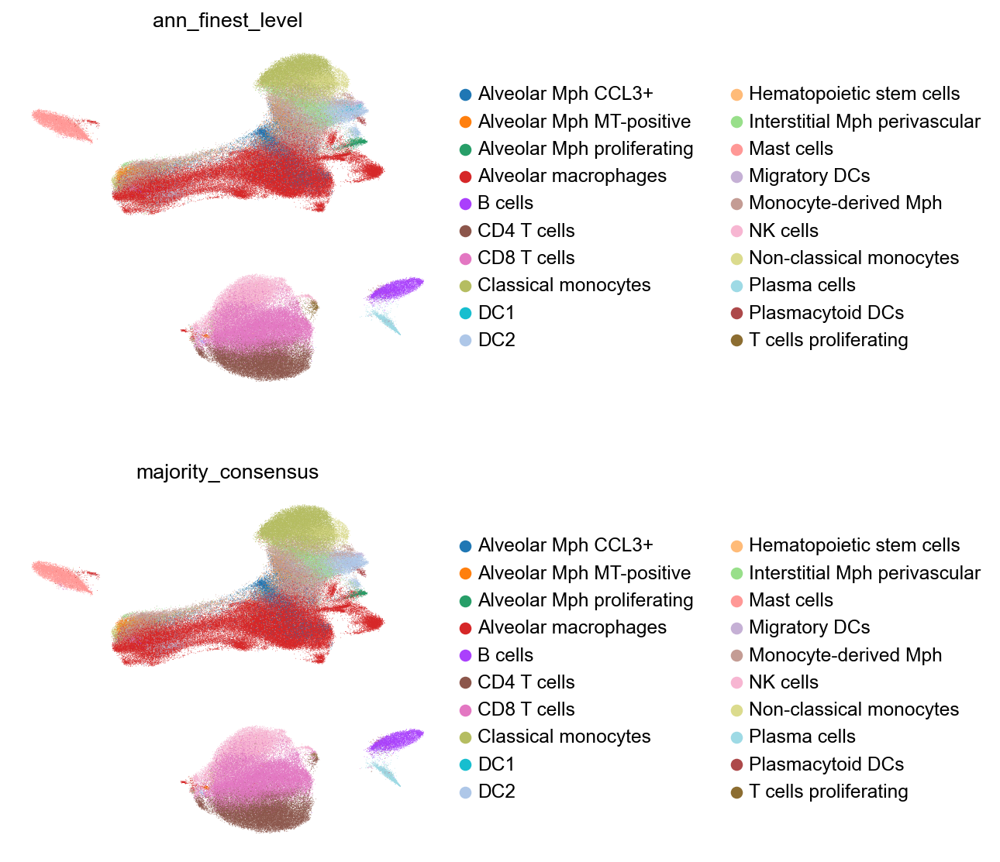

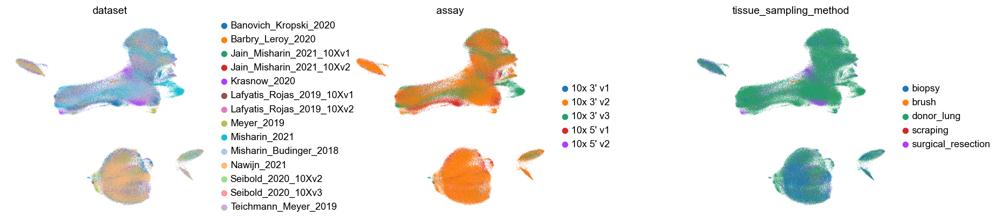

In [13]:
integration = 'f4e267c962'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors, 
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

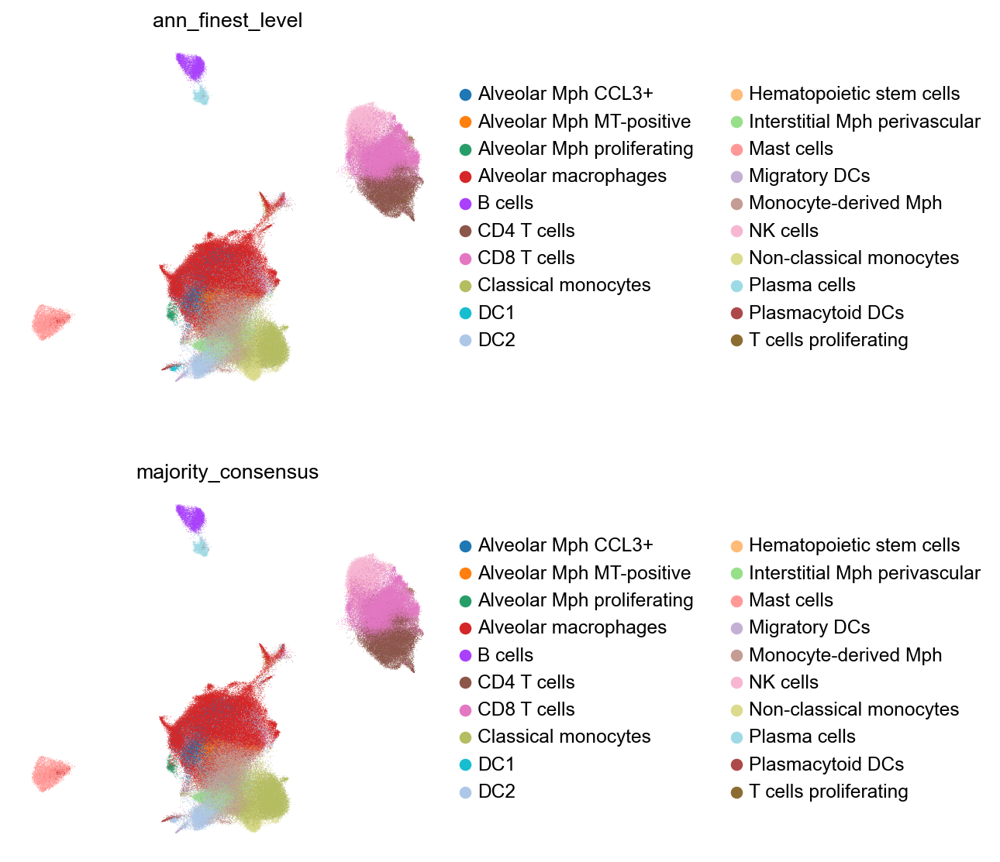

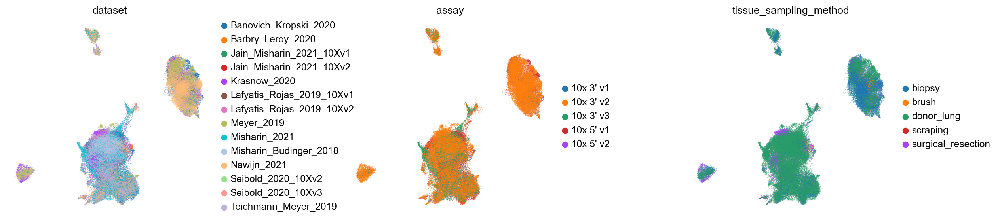

In [14]:
integration = 'f4e267c962'
strategy = 'lineage'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors, 
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

## scPoli

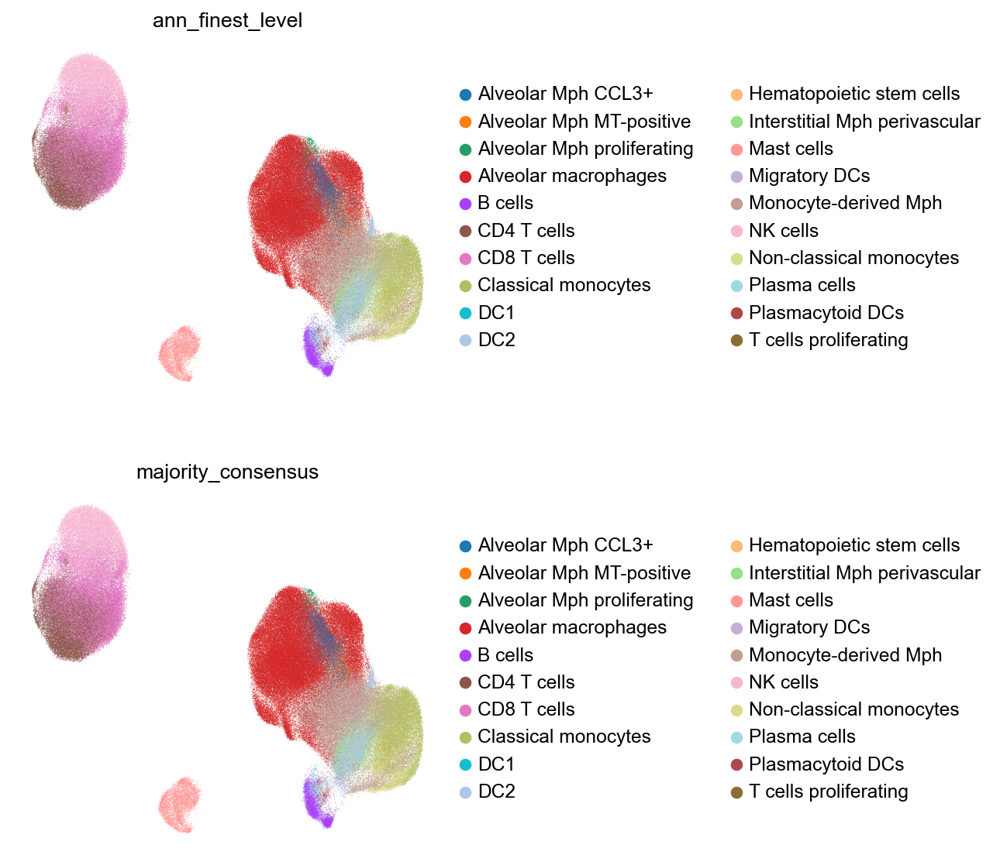

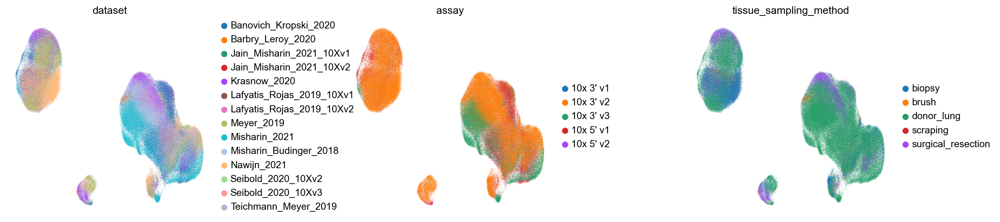

In [15]:
integration = '08c6548170'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors, 
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

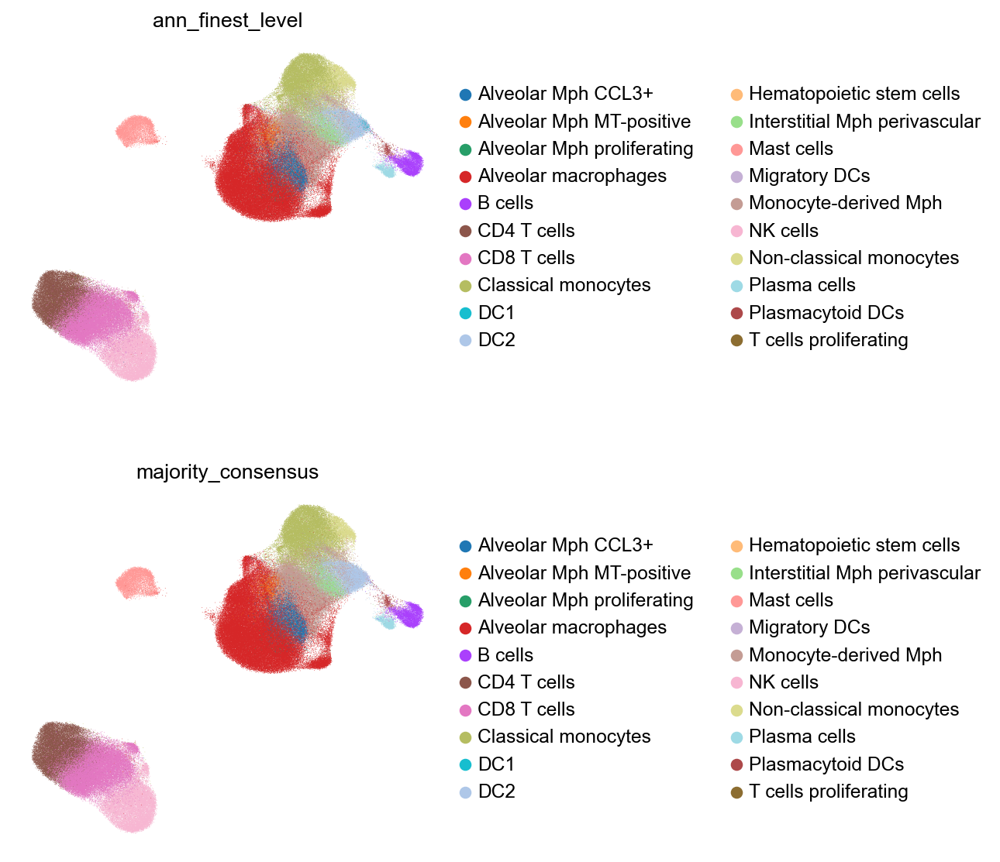

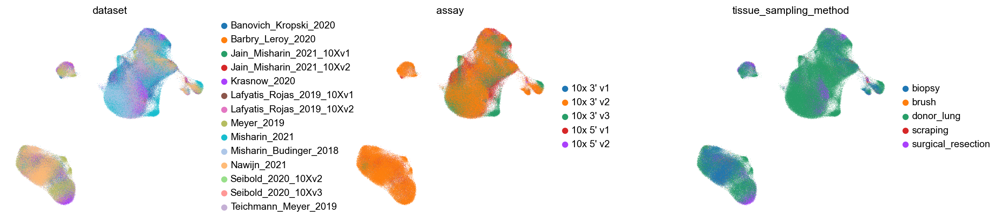

In [16]:
integration = '08c6548170'
strategy = 'lineage'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors, 
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

## DRVI

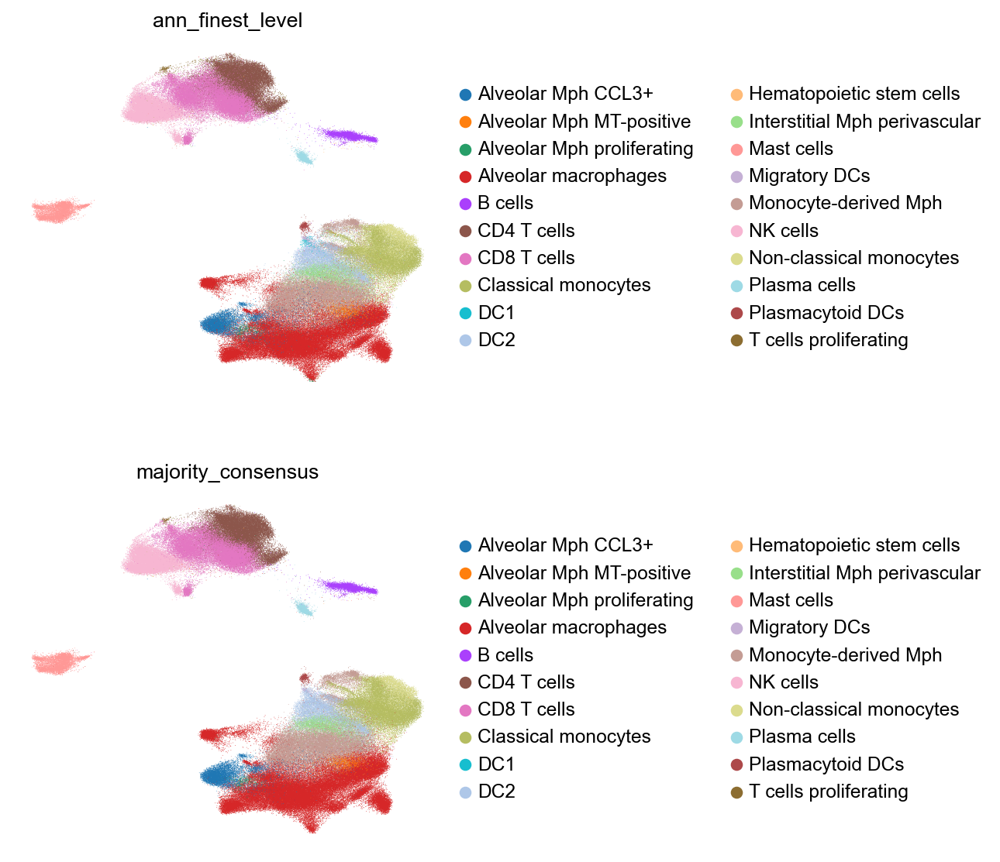

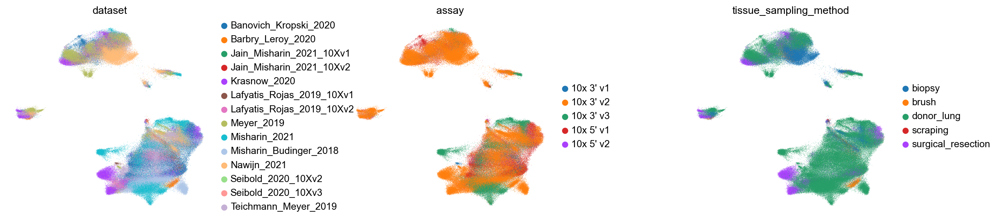

In [17]:
integration = '837ca7f62a'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors, 
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

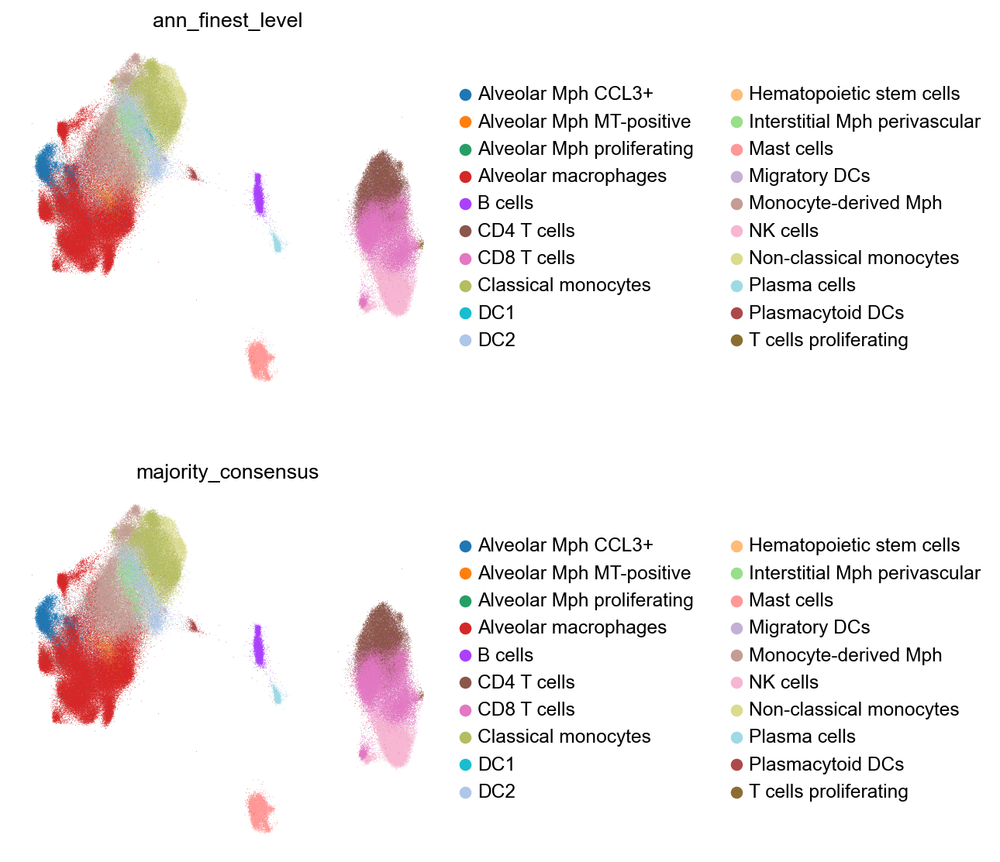

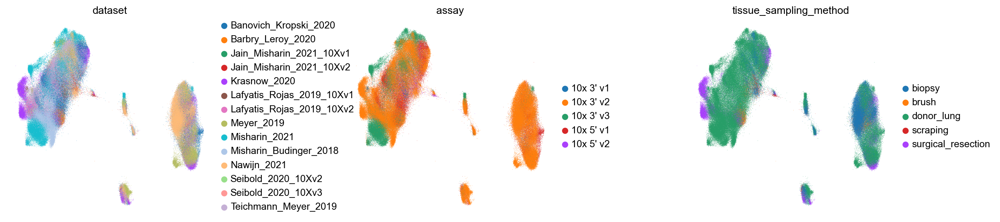

In [18]:
integration = '837ca7f62a'
strategy = 'lineage'
basis = f'X_umap--integration={integration}--strategy={strategy}'
sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors, 
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=batch_colors, 
    ncols=3,
    wspace=0.5,
)

# Graph similarity: Majority voting

<Axes: ylabel='Frequency'>

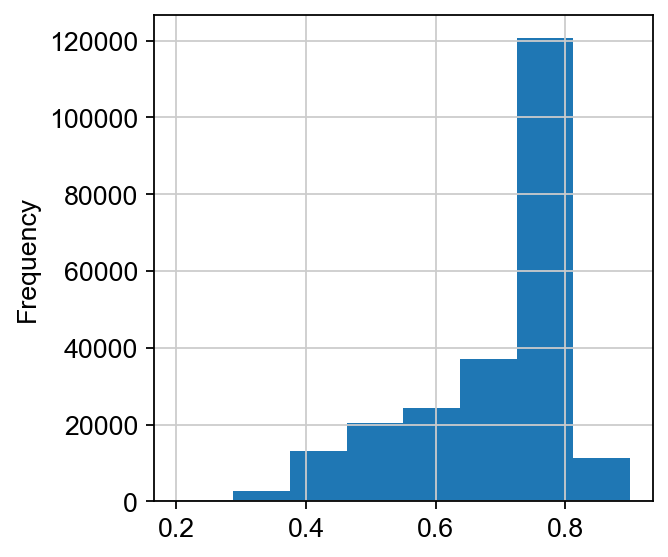

In [19]:
adata.obs['majority_consensus_agreement'].plot.hist(
    bins=adata.obs['majority_consensus_agreement'].nunique(),
)

In [20]:
def plot_histograms_per_cluster(adata, cluster_key, value_key, bins=30, height=1, aspect=5):
    df = adata.obs[[cluster_key, value_key]].copy()
    df[cluster_key] = df[cluster_key].astype('str')
    
    g = sns.displot(
        data=df,
        x=value_key,
        col=cluster_key,
        col_wrap=1,
        bins=bins,
        facet_kws={'sharex': False, 'sharey': False},
        height=height,
        aspect=aspect
    )

    g.set_titles(col_template="cluster = {col_name}", size=9)
    for ax in g.axes.flatten():
        ax.tick_params(labelsize=8)
        ax.grid(False)
    plt.tight_layout(h_pad=0.5)
    plt.show()

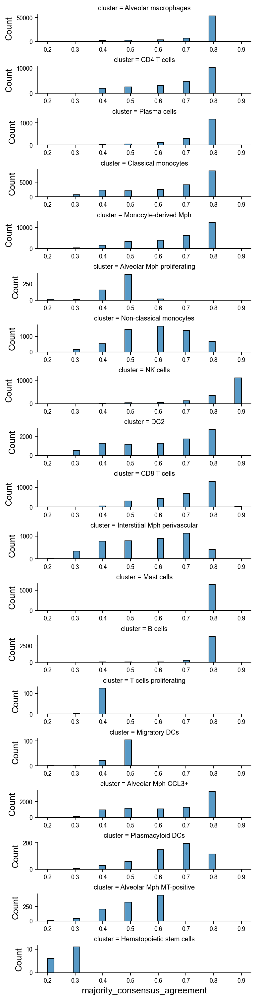

In [21]:
plot_histograms_per_cluster(
    adata,
    'majority_consensus',
    'majority_consensus_agreement'
)

In [22]:
def plot_per_cluster(adata, cluster_key, value_key):
    sns.catplot(
        data=adata.obs,
        y=cluster_key,
        x=value_key,
        kind='boxen',
    )

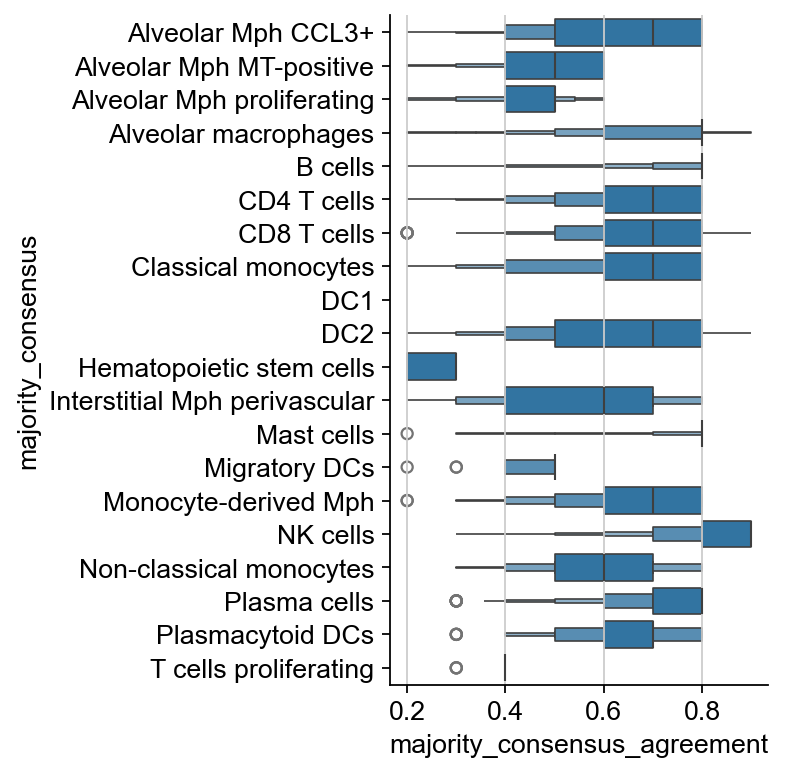

In [23]:
plot_per_cluster(
    adata,
    'majority_consensus',
    'majority_consensus_agreement'
)

In [24]:
def plot_avg_per_cluster(
    adata,
    cluster_key,
    value_key,
    agg='mean',
    height_base=0.3,
    width=7,
    return_df=False,
):
    df = adata.obs.groupby(cluster_key, observed=True)[value_key].agg(agg).sort_values(ascending=False).reset_index()
    
    height = 1 + height_base * df[cluster_key].nunique()
    aspect = width / height
    g = sns.catplot(
        data=df,
        x=value_key,
        y=cluster_key,
        kind="bar",
        order=df[cluster_key],
        height=height,
        aspect=aspect,
        sharex=False
    )

    g.ax.set_title(f'{agg.capitalize()} {value_key} per {cluster_key}')
    sns.despine(trim=True)

    # Annotate bars
    for bar in g.ax.patches:
        width = bar.get_width()
        g.ax.text(width + width*0.01, bar.get_y() + bar.get_height()/2, f'{width:.2f}', va='center')

    plt.tight_layout()
    plt.show()
    
    if return_df:
        return df

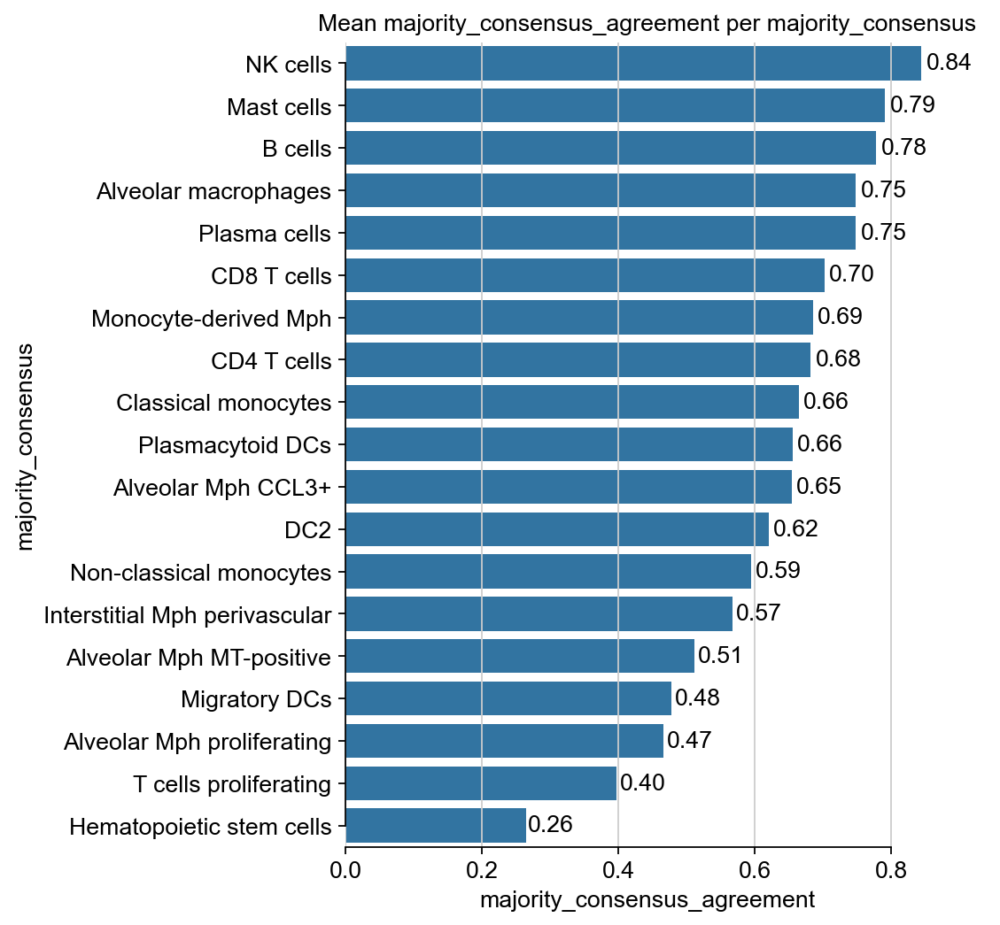

In [25]:
plot_avg_per_cluster(adata, 'majority_consensus', 'majority_consensus_agreement')

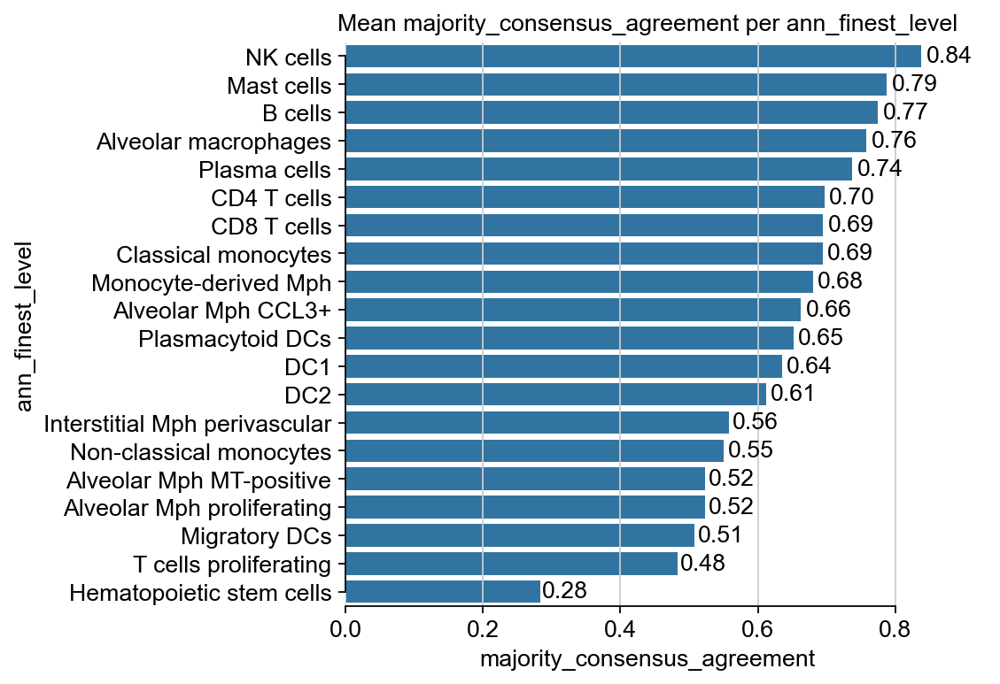

In [114]:
plot_avg_per_cluster(adata, 'ann_finest_level', 'majority_consensus_agreement', height_base=0.2)

In [27]:
adata.obs['majority_consensus_disagreement'] = 1 - adata.obs['majority_consensus_agreement']

In [28]:
difficult_cell_types = ['DC1', 'DC2', 'Hematopoietic stem cells', 'T cells proliferating']

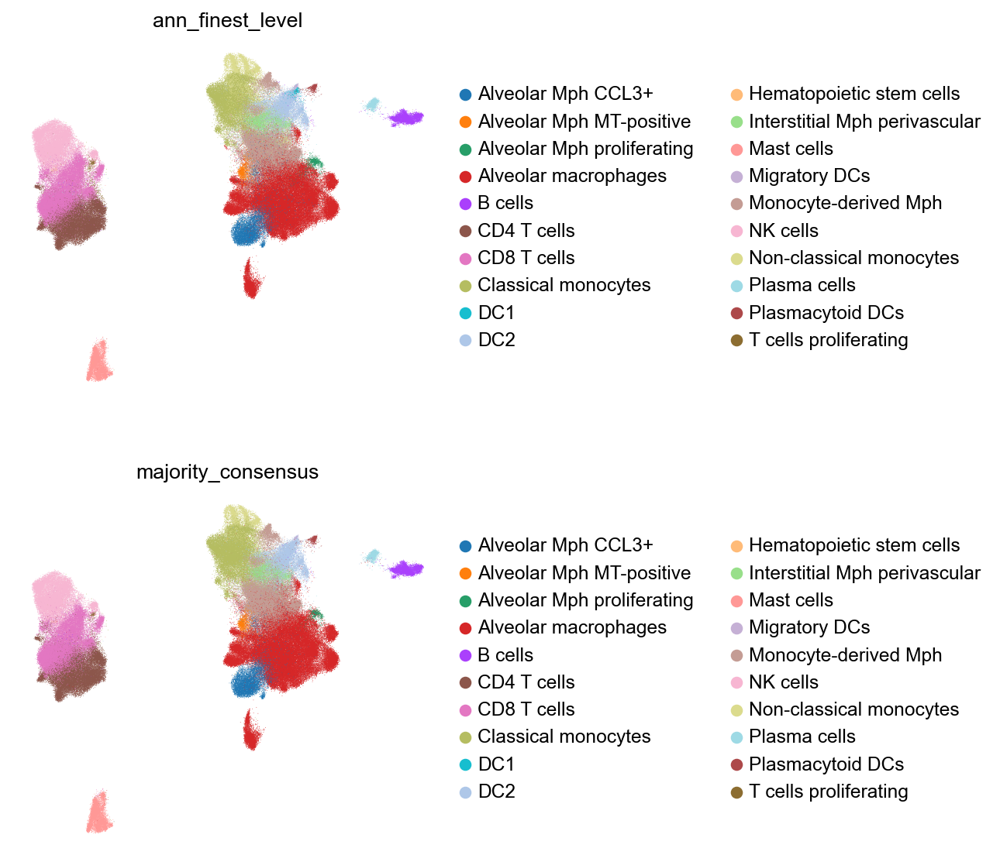

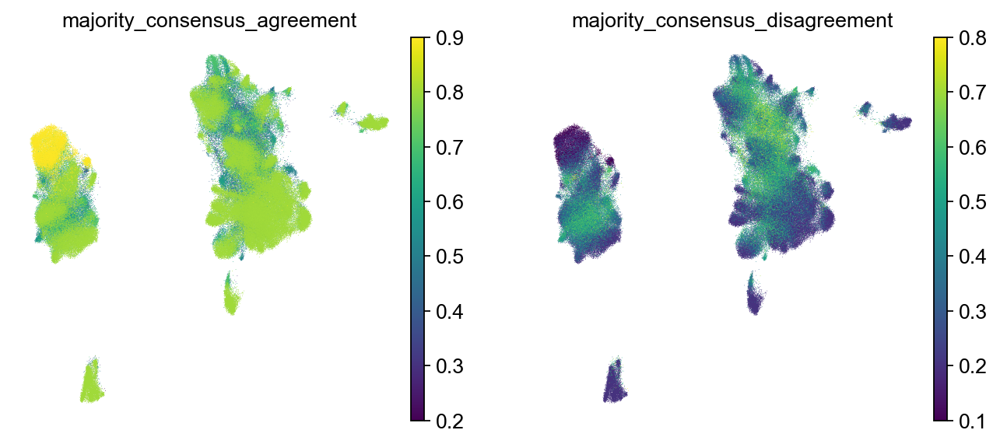

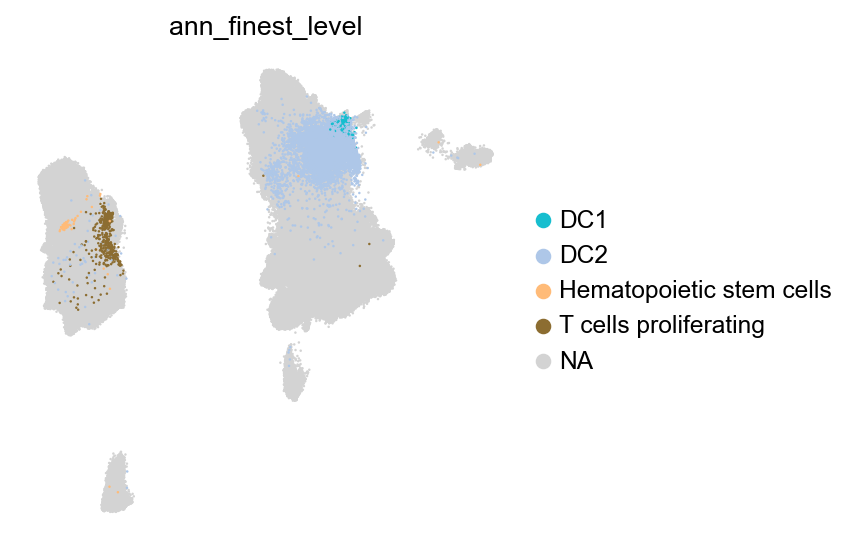

In [29]:
integration = '2062d25075'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'

sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors,
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['majority_consensus_agreement', 'majority_consensus_disagreement'],
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['ann_finest_level'],
    groups=difficult_cell_types,
    size=5,
)

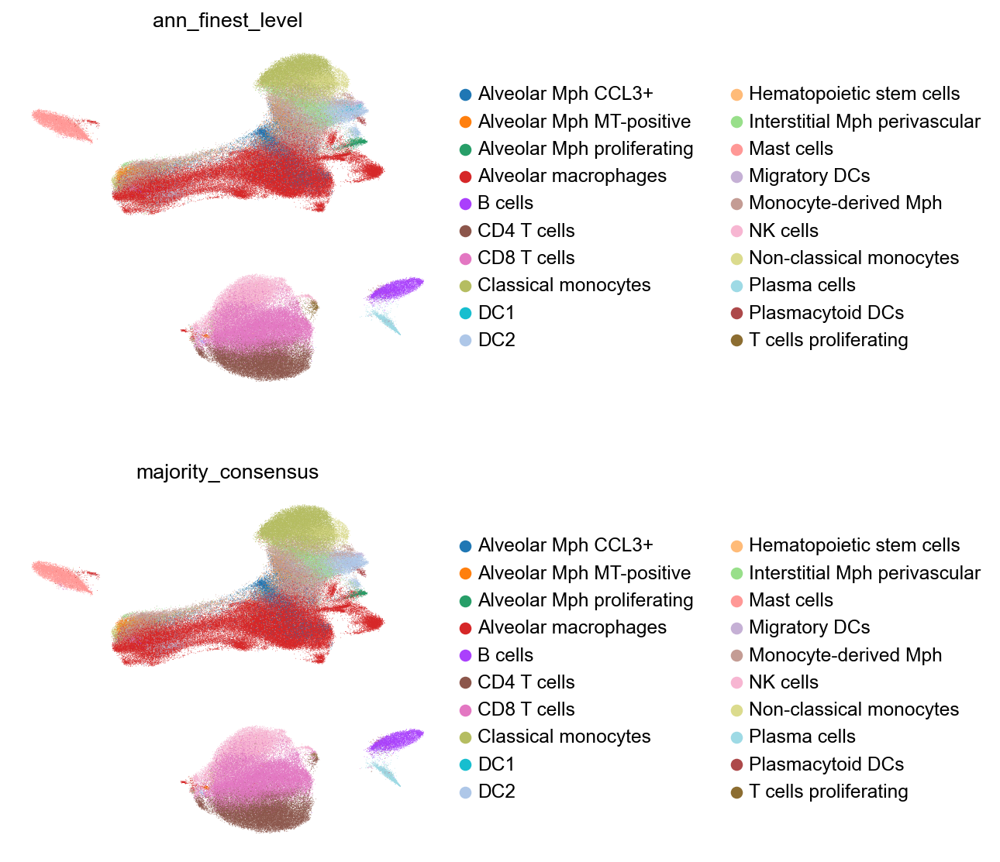

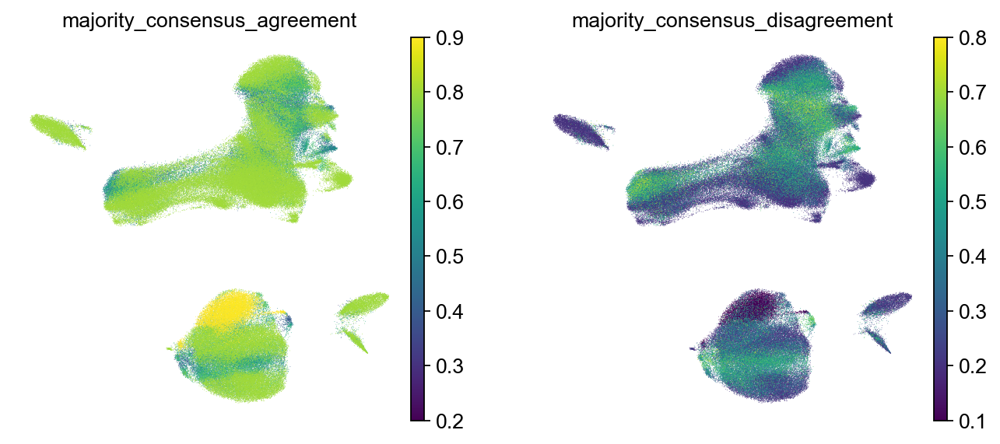

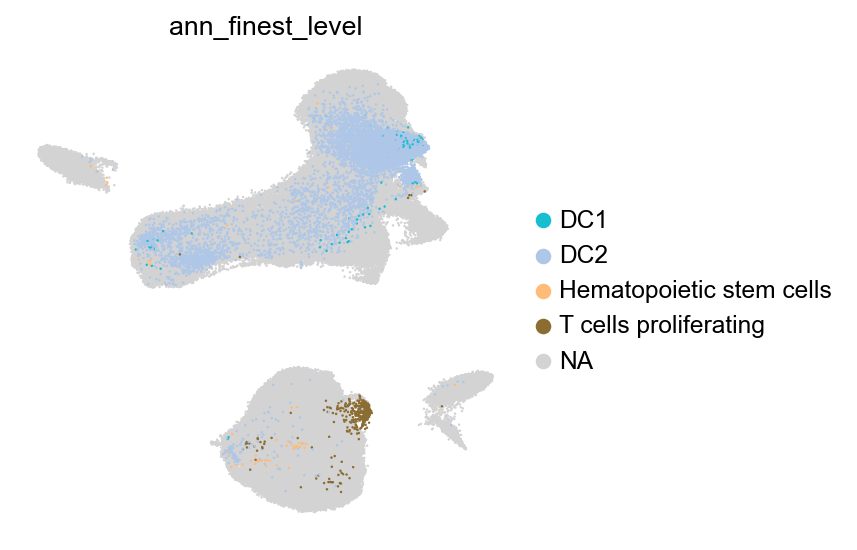

In [30]:
integration = 'f4e267c962'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'

sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors,
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['majority_consensus_agreement', 'majority_consensus_disagreement'],
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['ann_finest_level'],
    groups=difficult_cell_types,
    size=5,
)

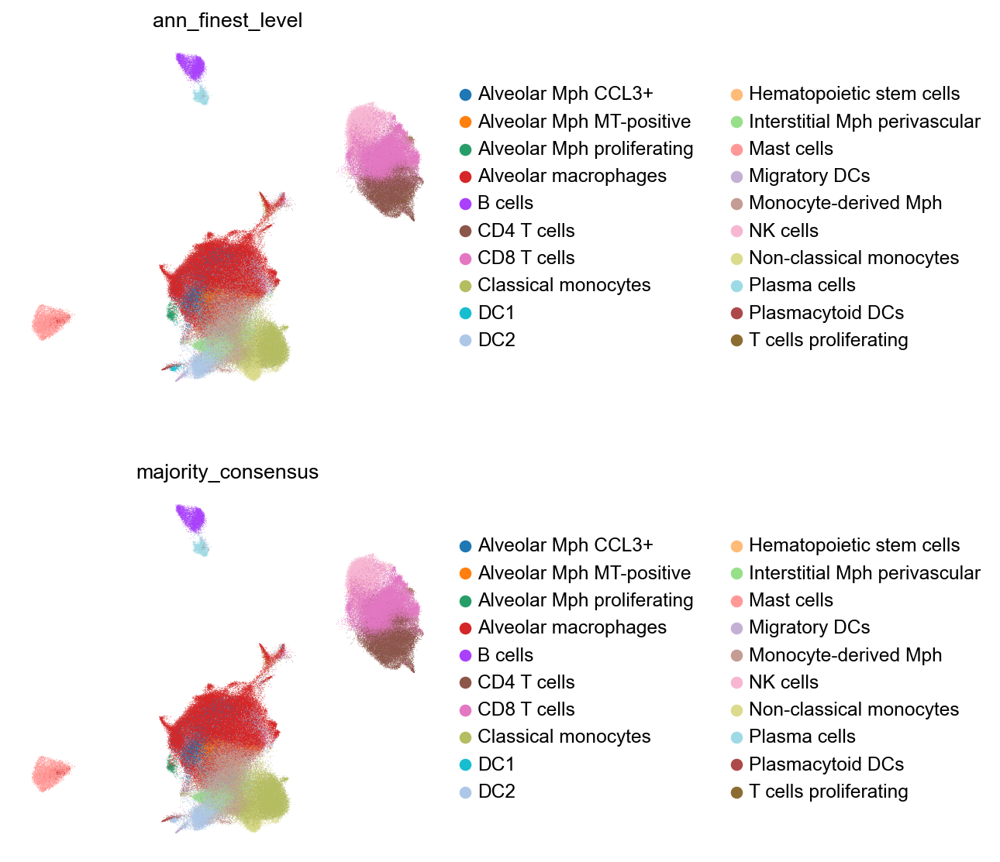

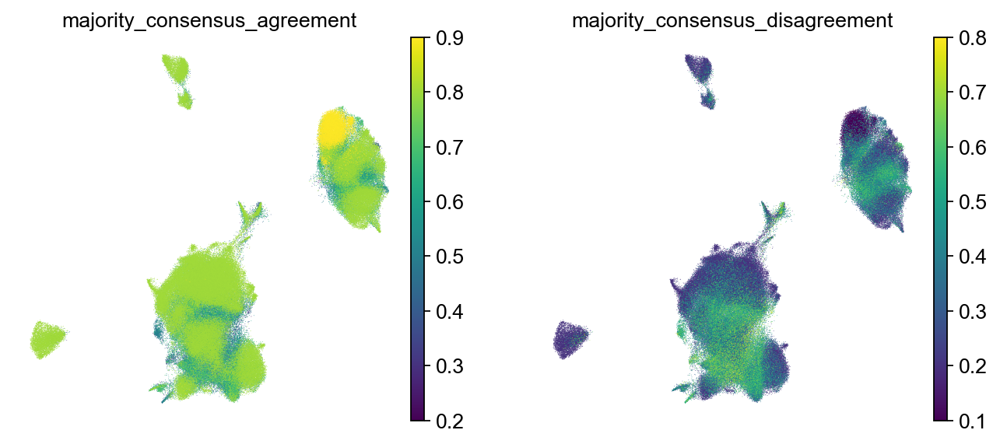

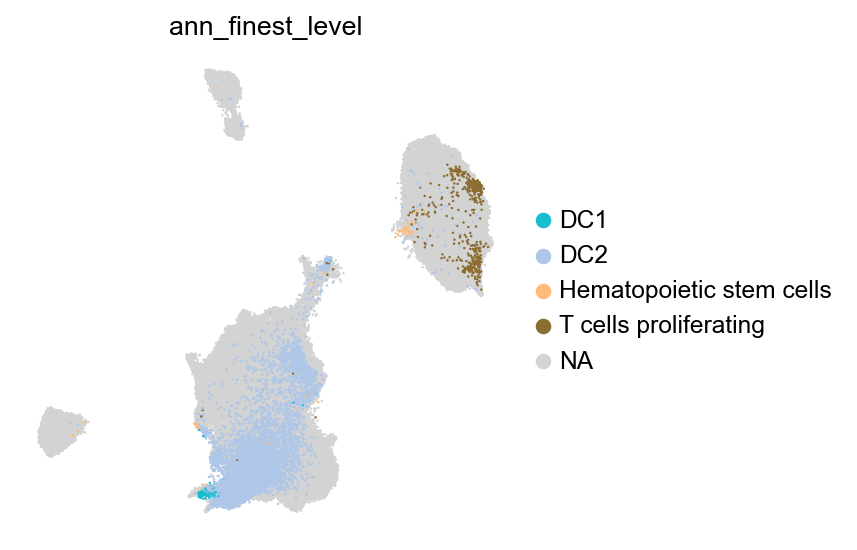

In [31]:
integration = 'f4e267c962'
strategy = 'lineage'
basis = f'X_umap--integration={integration}--strategy={strategy}'

sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors,
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['majority_consensus_agreement', 'majority_consensus_disagreement'],
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['ann_finest_level'],
    groups=difficult_cell_types,
    size=5,
)

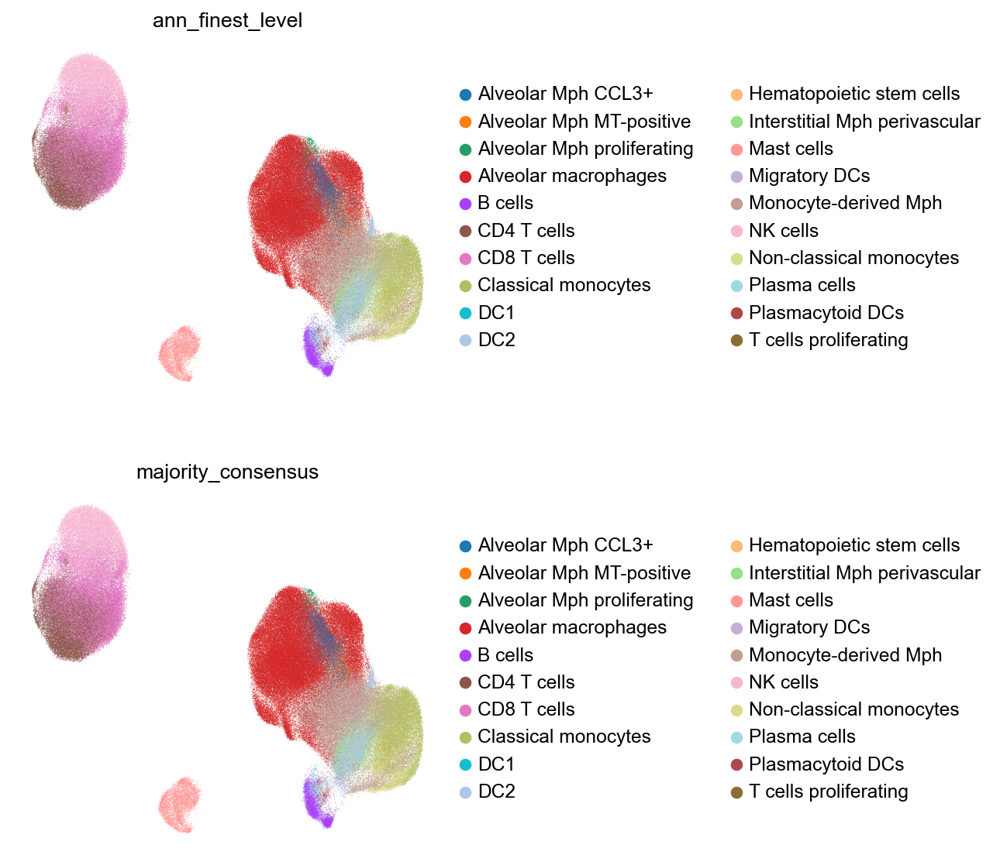

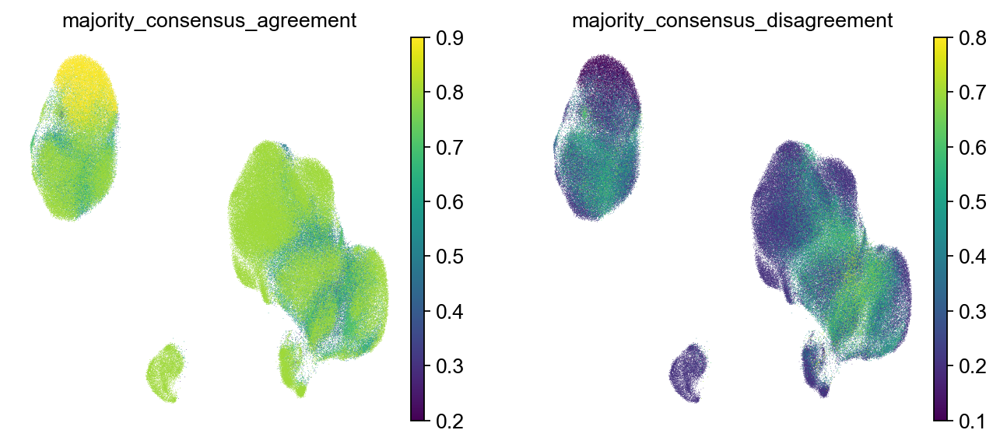

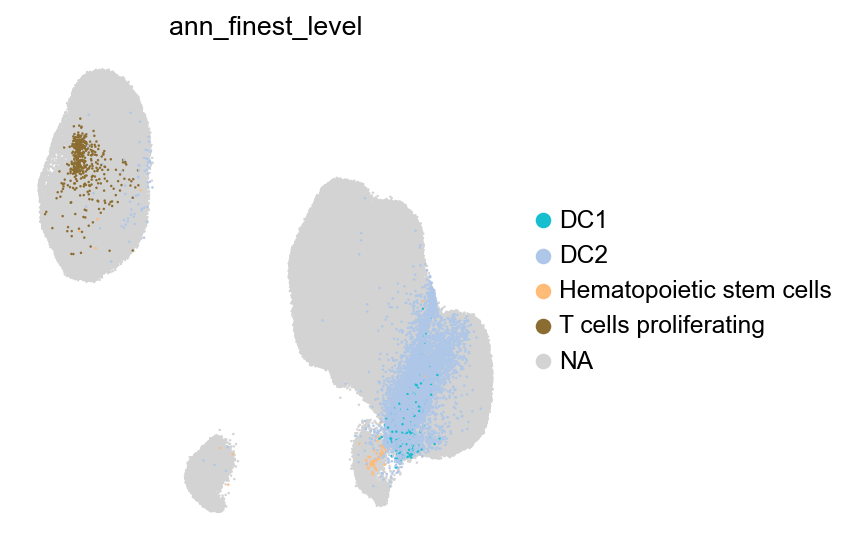

In [32]:
integration = '08c6548170'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'

sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors,
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['majority_consensus_agreement', 'majority_consensus_disagreement'],
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['ann_finest_level'],
    groups=difficult_cell_types,
    size=5,
)

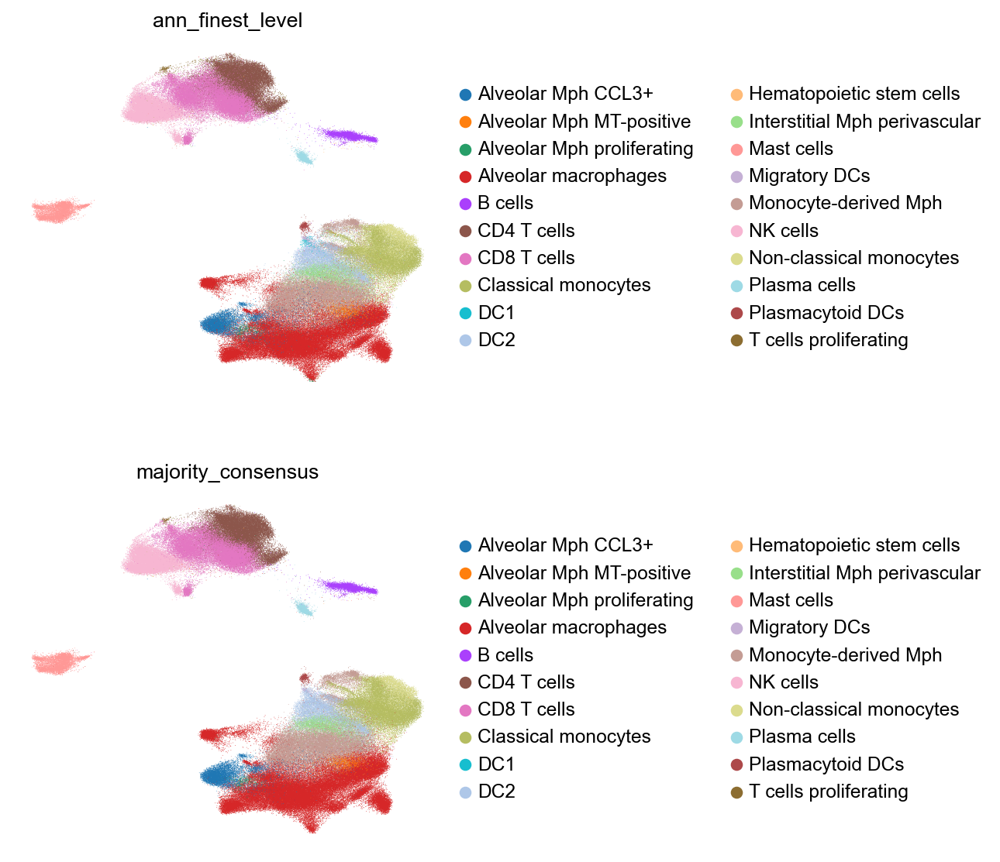

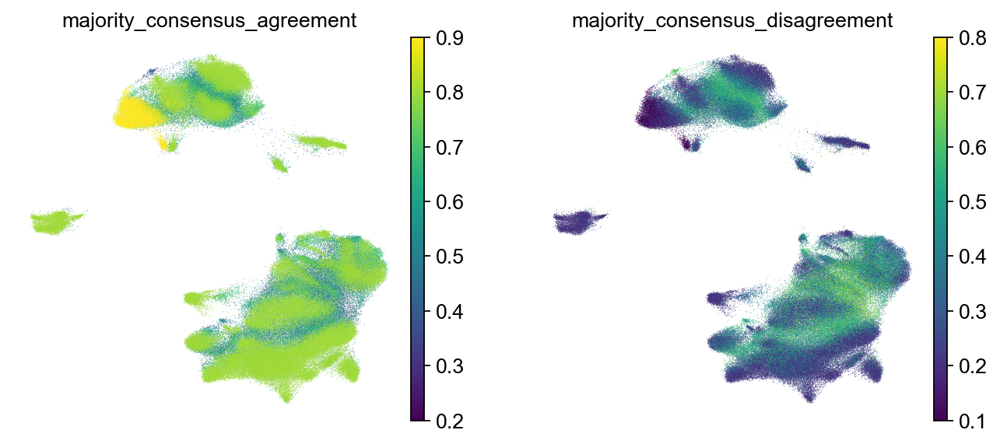

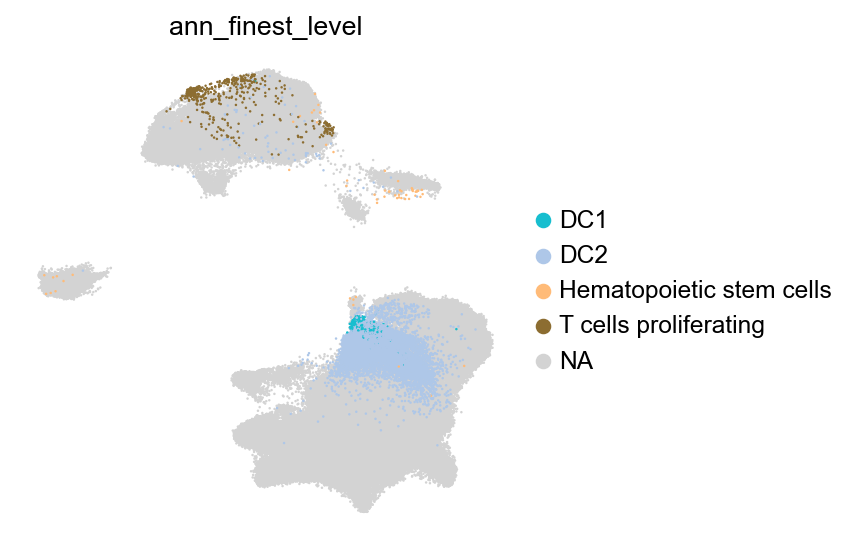

In [33]:
integration = '837ca7f62a'
strategy = 'global'
basis = f'X_umap--integration={integration}--strategy={strategy}'

sc.pl.embedding(
    adata,
    basis=basis,
    color=annotation_colors,
    ncols=1,
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['majority_consensus_agreement', 'majority_consensus_disagreement'],
)

sc.pl.embedding(
    adata,
    basis=basis,
    color=['ann_finest_level'],
    groups=difficult_cell_types,
    size=5,
)

# Graph similarity: distance distribution

In [34]:
from graph_similarity import da, \
    compare_distances, plot_distances_scatter, plot_ranked_distances

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [35]:
def plot_diff_per_clusters(
    adata,
    cluster_key,
    diff_key,
    x_label=None,
    width=6,
    height_factor=0.2,
    figsize=None
):
    if x_label is None:
        x_label = diff_key
    
    value_counts = adata.obs[cluster_key].astype(str).value_counts()
    diff_per_cluster = adata.obs.groupby(
        cluster_key,
        observed=True
    )[diff_key].mean()
    diff_per_cluster = diff_per_cluster.sort_values()

    # plot
    if figsize is None:
        figsize = (width, len(diff_per_cluster) * height_factor)
    fig, ax = plt.subplots(figsize=figsize)
    
    diff_per_cluster.plot.barh(ax=ax)
    
    for i, (k, v) in enumerate(diff_per_cluster.items()):
        ax.text(v, i, f'{value_counts[k]}', va='center')
    
    ax.grid(False)
    ax.set_xlabel(x_label)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.show()
    
    return diff_per_cluster

In [36]:
def load_distances(integrations):
    for integration in integrations:
        for obsp_key in ['connectivities', 'distances']:
            x = adata.obsp[f'{obsp_key}--{integration}']
            if isinstance(x, da.Array):
                adata.obsp[f'{obsp_key}--{integration}'] = x.compute()

In [80]:
integration1 = 'integration=2062d25075--strategy=global'  # scVI
integration2 = 'integration=f4e267c962--strategy=global'  # Harmony
integration2 = 'integration=08c6548170--strategy=global'  # scpoli

In [81]:
load_distances([integration1, integration2])

In [82]:
%%time
int1 = integration1.replace('integration=', '').replace('strategy=', '')
int2 = integration2.replace('integration=', '').replace('strategy=', '')
comp = f'{int1}-vs-{int2}'

adata.obs[[
    f'avg_distance_1:{comp}',
    f'avg_distance_2:{comp}',
    f'avg_difference:{comp}',
    f'avg_distance_diff:{comp}',
    f'spearman_correlation:{comp}',
]] = compare_distances(
    adata,
    obsp_key_1=f'distances--{integration1}',
    obsm_key_1=f'X_emb--{integration1}',
    obsp_key_2=f'distances--{integration2}',
    obsm_key_2=f'X_emb--{integration2}',
    k_max=100,
    scale_distances=True,
    log_scale_diffs=False,
)

comp = f'{int2}-vs-{int1}'
adata.obs[[
    f'avg_distance_1:{comp}',
    f'avg_distance_2:{comp}',
    f'avg_difference:{comp}',
    f'avg_distance_diff:{comp}',
    f'spearman_correlation:{comp}',
]] = compare_distances(
    adata,
    obsp_key_1=f'distances--{integration2}',
    obsm_key_1=f'X_emb--{integration2}',
    obsp_key_2=f'distances--{integration1}',
    obsm_key_2=f'X_emb--{integration1}',
    k_max=100,
    scale_distances=True,
    log_scale_diffs=False,
)

Symmetrize matrix: 100%|██████████| 1/1 [00:01<00:00,  1.32s/it]


Determine missing distances...
15061972 edges to recompute


Computing distances: 3it [00:00, 4932.54it/s]             


Get kNN...
Calculate degress...
scale distances by 0.9 quantile...
Calculate differences...


Symmetrize matrix: 100%|██████████| 1/1 [00:01<00:00,  1.34s/it]


Determine missing distances...
14164871 edges to recompute


Computing distances: 3it [00:00, 4641.43it/s]             


Get kNN...
Calculate degress...
scale distances by 0.9 quantile...
Calculate differences...
CPU times: user 24.6 s, sys: 2.34 s, total: 26.9 s
Wall time: 34.1 s


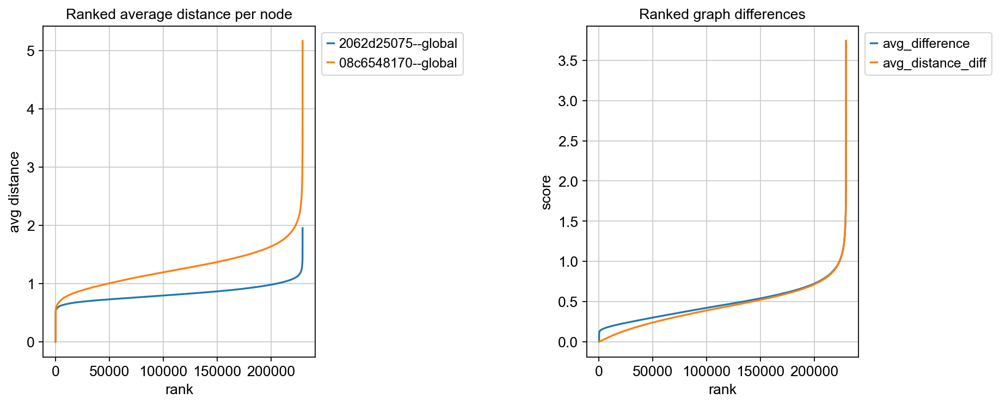

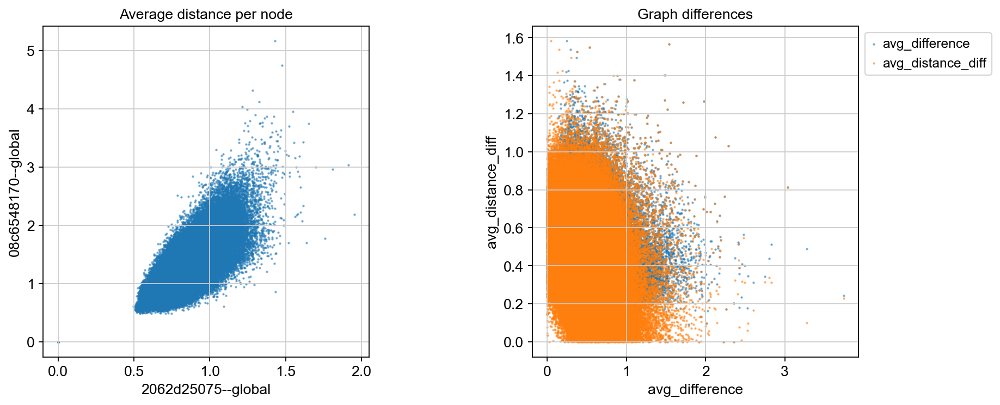

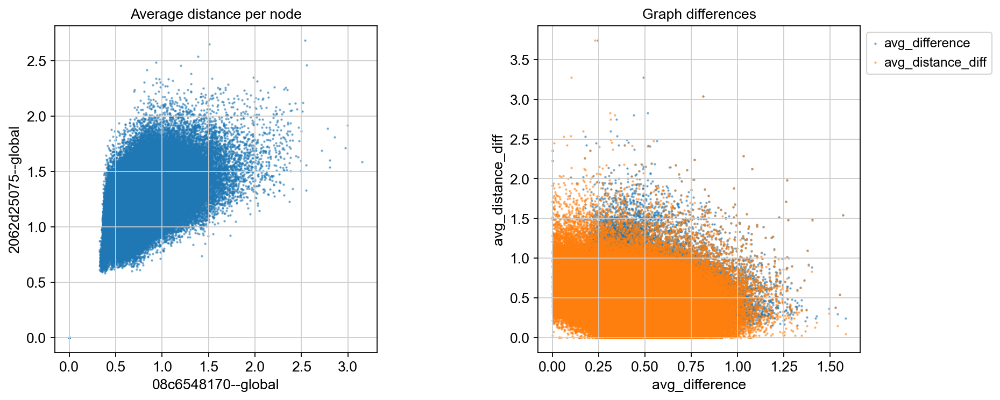

In [88]:
plot_ranked_distances(adata, int1, int2)
plot_distances_scatter(adata, int1, int2, s=1, alpha=0.5)
plot_distances_scatter(adata, int2, int1, s=1, alpha=0.5)

In [89]:
comparisons = [
    f'{int1}-vs-{int2}',
    f'{int2}-vs-{int1}'
]

In [92]:
metrics = [
    'avg_distance_1',
    'avg_distance_2',
    'avg_difference',
    # 'avg_distance_diff',
    # 'spearman_correlation'
]

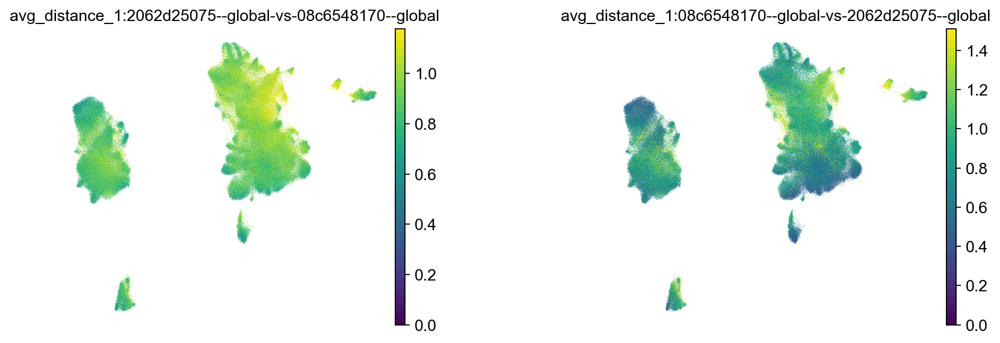

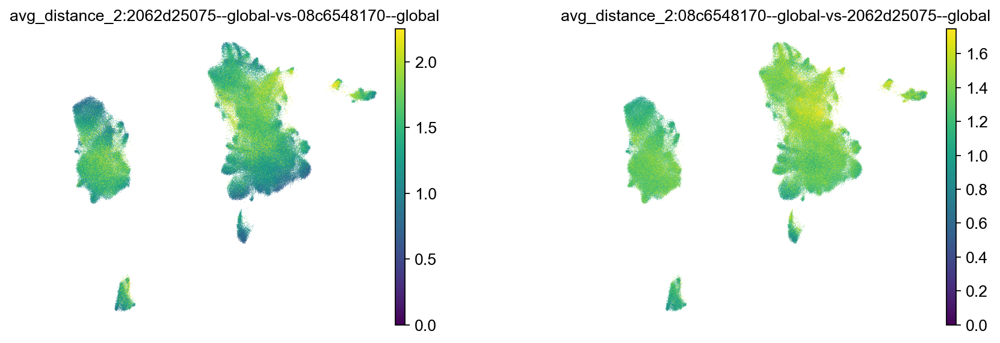

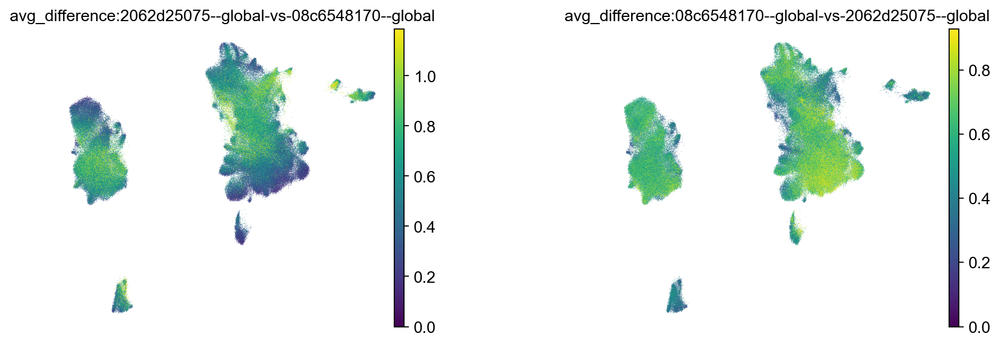

In [93]:
for _metric in metrics:
    colors = [f'{_metric}:{comparison}' for comparison in comparisons]
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=colors,
        cmap='viridis',
        # size=5,
        ncols=len(metrics),
        wspace=0.5,
        # vmin=0,
        vmax=adata.obs[colors].quantile(0.99).tolist(),
        sort_order=True,
    )

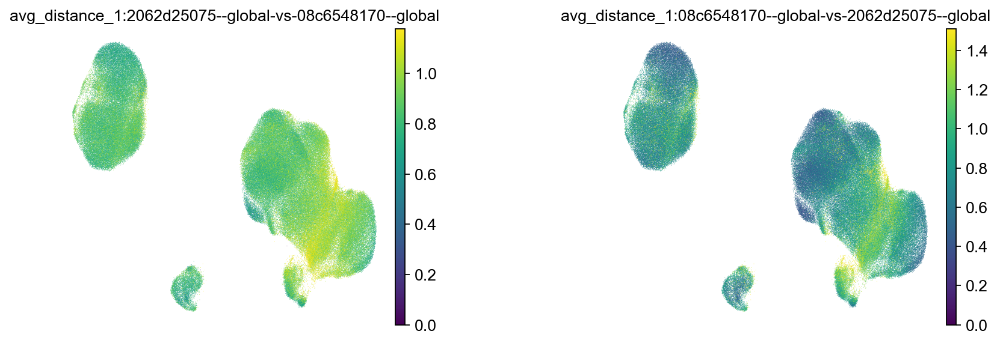

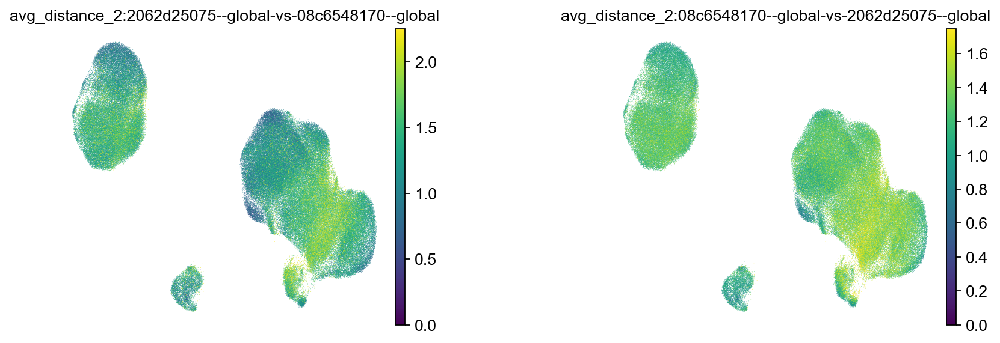

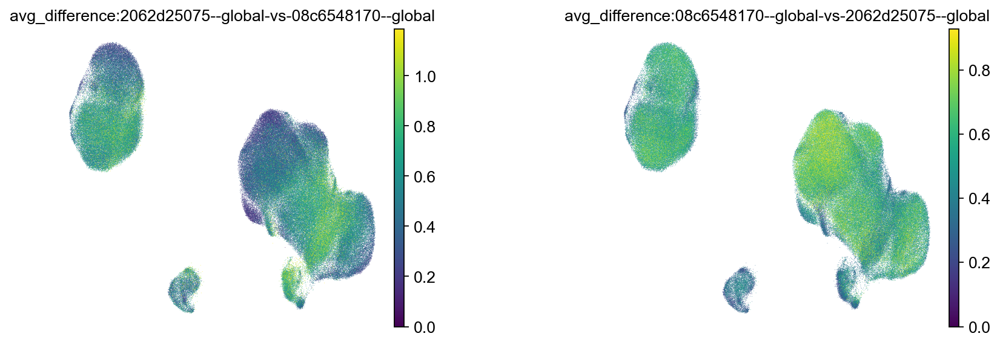

In [95]:
for _metric in metrics:
    colors = [f'{_metric}:{comparison}' for comparison in comparisons]
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration2}',
        color=colors,
        cmap='viridis',
        # size=5,
        ncols=len(metrics),
        wspace=0.5,
        # vmin=0,
        vmax=adata.obs[colors].quantile(0.99).tolist(),
        sort_order=True,
    )

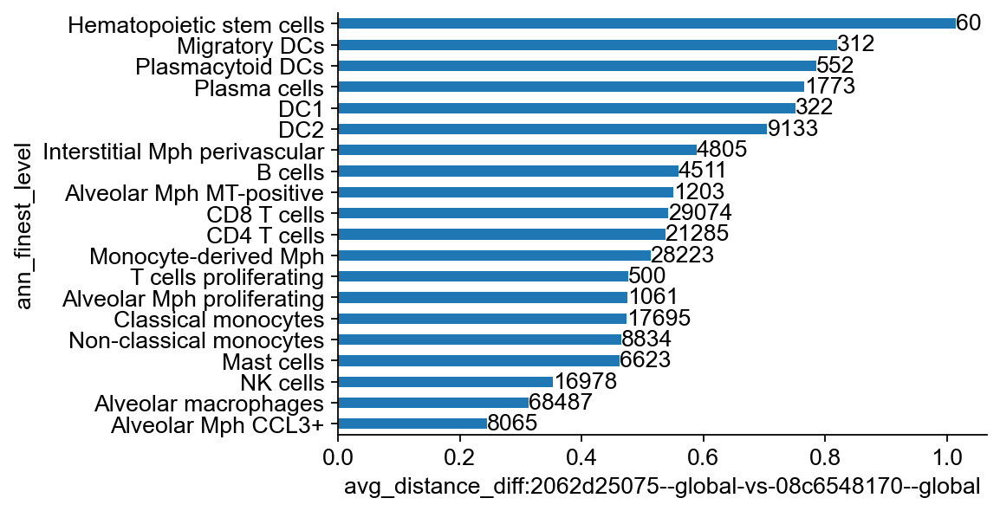

ann_finest_level
Alveolar Mph CCL3+               0.244235
Alveolar macrophages             0.313558
NK cells                         0.352583
Mast cells                       0.461592
Non-classical monocytes          0.464457
Classical monocytes              0.473438
Alveolar Mph proliferating       0.475114
T cells proliferating            0.476401
Monocyte-derived Mph             0.512811
CD4 T cells                      0.537118
CD8 T cells                      0.542202
Alveolar Mph MT-positive         0.550747
B cells                          0.558513
Interstitial Mph perivascular    0.588690
DC2                              0.704667
DC1                              0.751552
Plasma cells                     0.765632
Plasmacytoid DCs                 0.785123
Migratory DCs                    0.819293
Hematopoietic stem cells         1.014197
Name: avg_distance_diff:2062d25075--global-vs-08c6548170--global, dtype: float64

In [96]:
plot_diff_per_clusters(
    adata,
    'ann_finest_level',
    f'avg_distance_diff:{int1}-vs-{int2}',
)

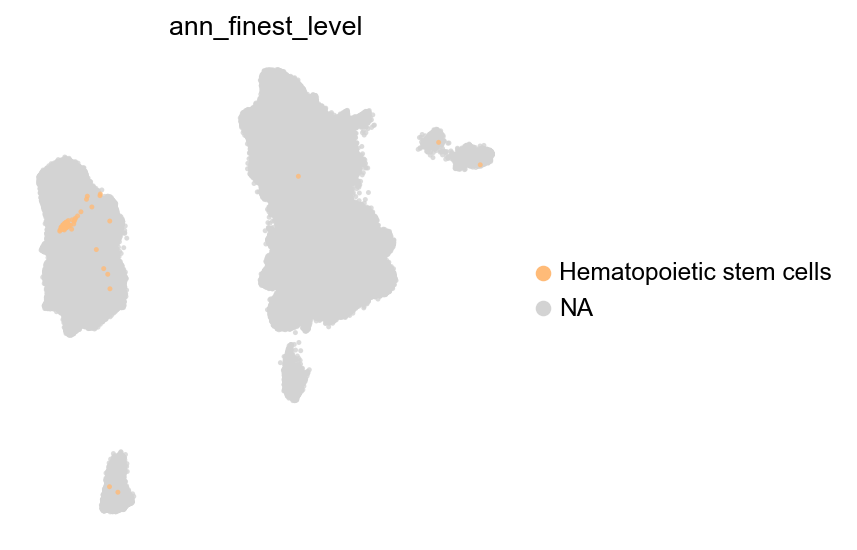

In [107]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color='ann_finest_level',
    groups='Hematopoietic stem cells',
    size=20,
    alpha=0.8,
    ncols=1,
)

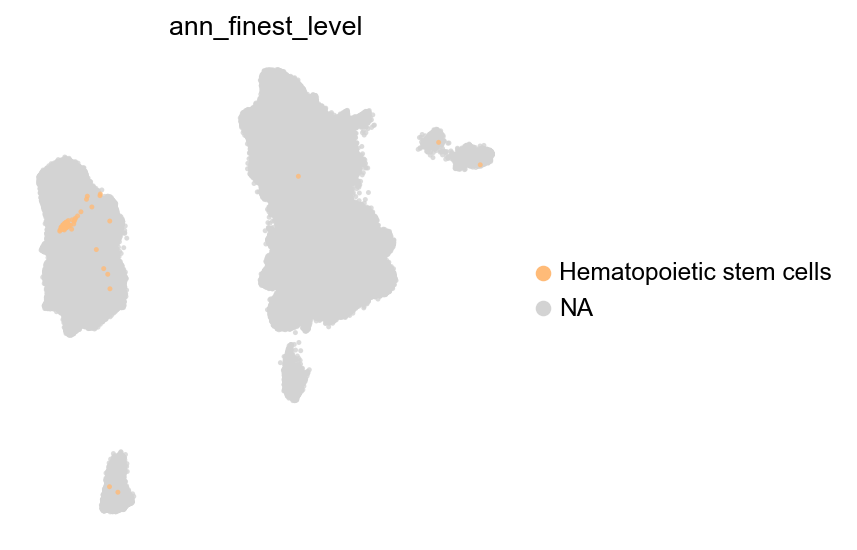

In [107]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color='ann_finest_level',
    groups='Plasma cells',
    size=20,
    alpha=0.8,
    ncols=1,
)

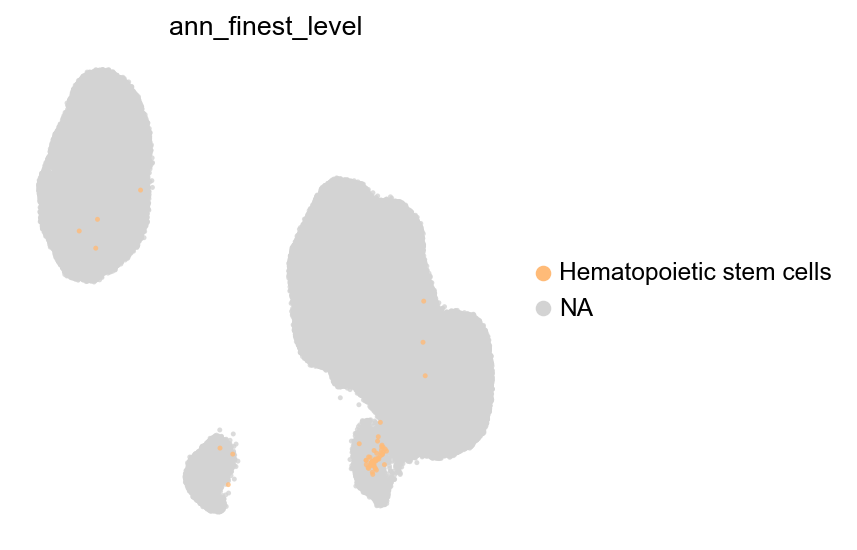

In [109]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color='ann_finest_level',
    groups='Hematopoietic stem cells',
    size=20,
    alpha=0.8,
    ncols=1,
)

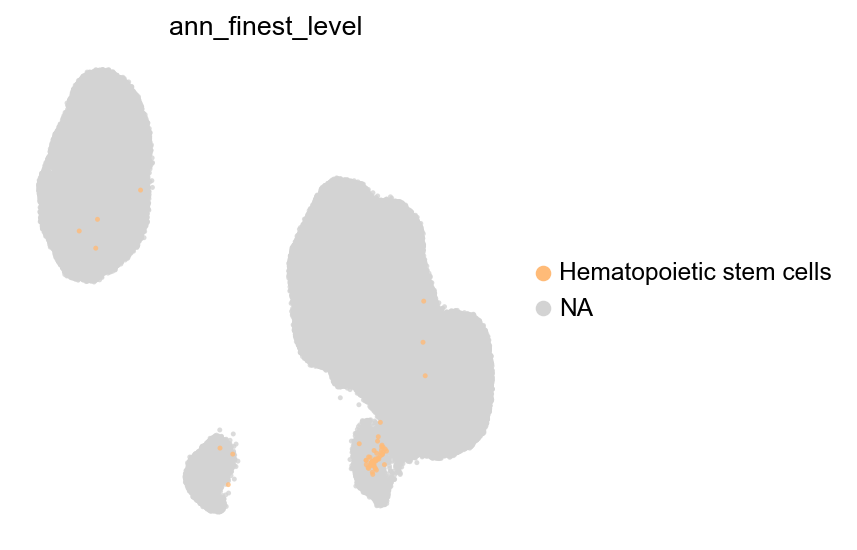

In [109]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color='ann_finest_level',
    groups='plasma cells',
    size=20,
    alpha=0.8,
    ncols=1,
)

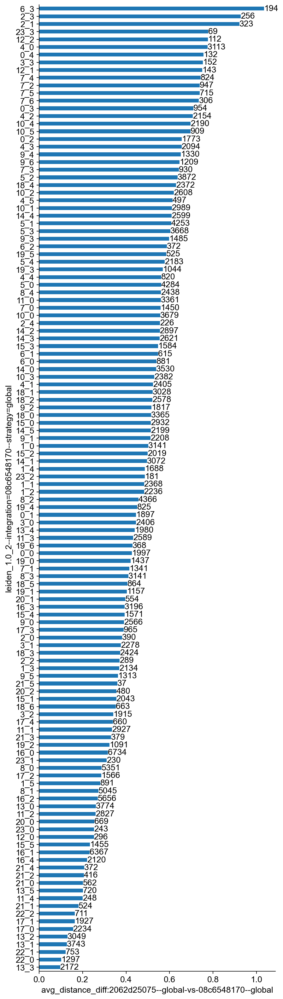

leiden_1.0_2--integration=08c6548170--strategy=global
13_3    0.096612
22_0    0.101084
22_1    0.121606
13_1    0.127266
13_2    0.130773
          ...   
12_2    0.776634
23_3    0.778214
2_1     0.921730
2_3     0.927803
6_3     1.035135
Name: avg_distance_diff:2062d25075--global-vs-08c6548170--global, Length: 126, dtype: float64

In [111]:
cluster_prefix = 'leiden_1.0_2'
plot_diff_per_clusters(
    adata,
    f'{cluster_prefix}--{integration2}',
    f'avg_distance_diff:{int1}-vs-{int2}',
)

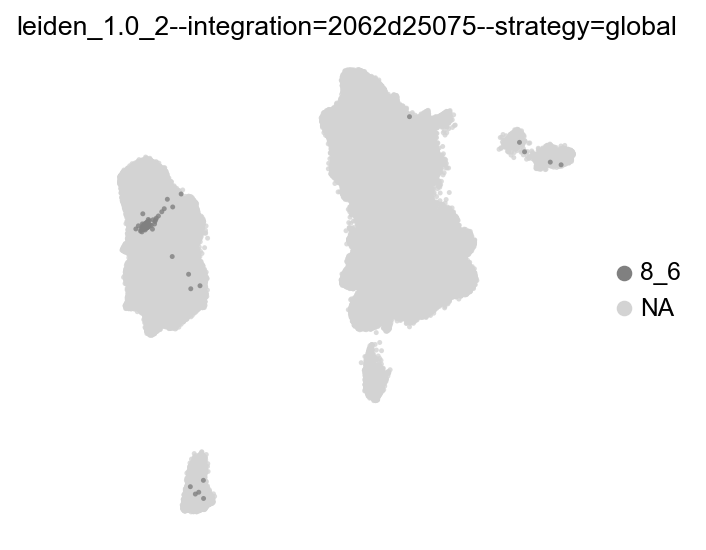

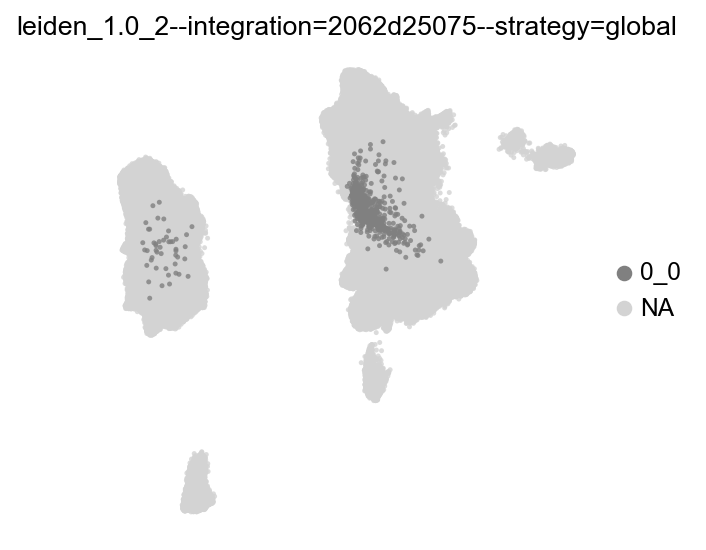

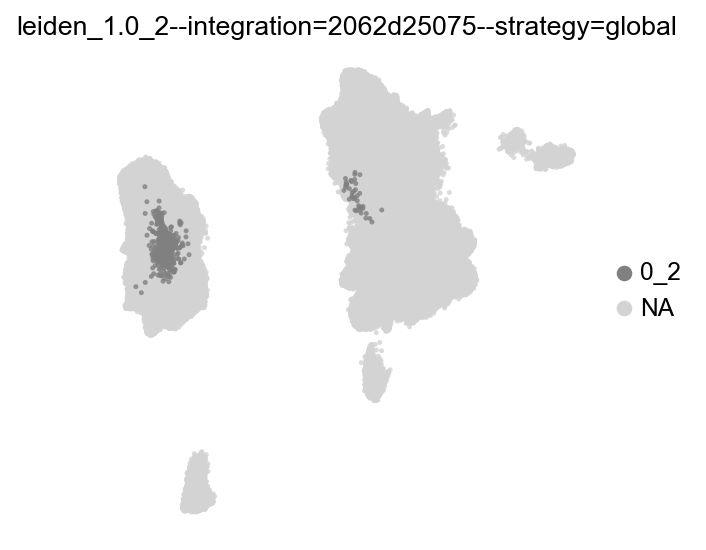

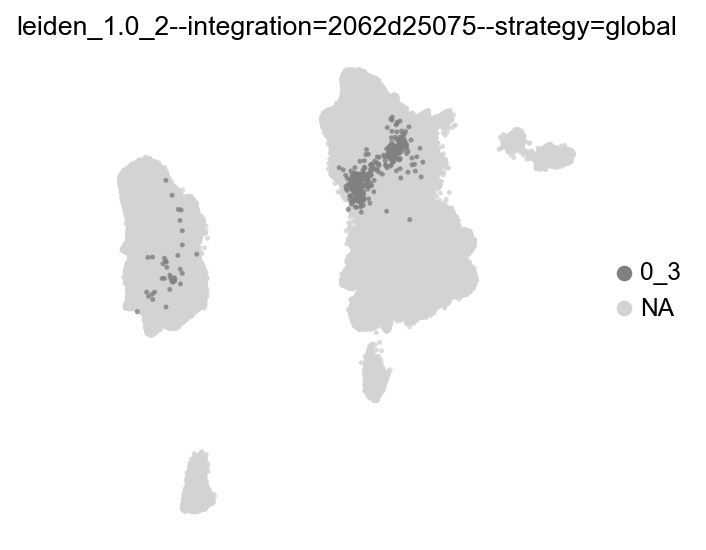

In [108]:
for group in ['8_6', '0_0', '0_2', '0_3']:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=f'{cluster_prefix}--{integration1}',
        groups=group,
        size=20,
        alpha=0.8,
        ncols=1,
    )

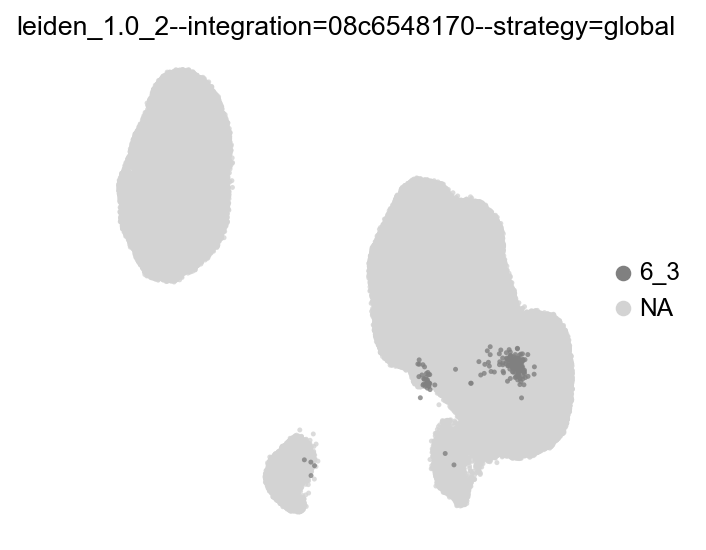

In [112]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration2}',
    color=f'{cluster_prefix}--{integration2}',
    groups='6_3',
    size=20,
    alpha=0.8,
    ncols=1,
)

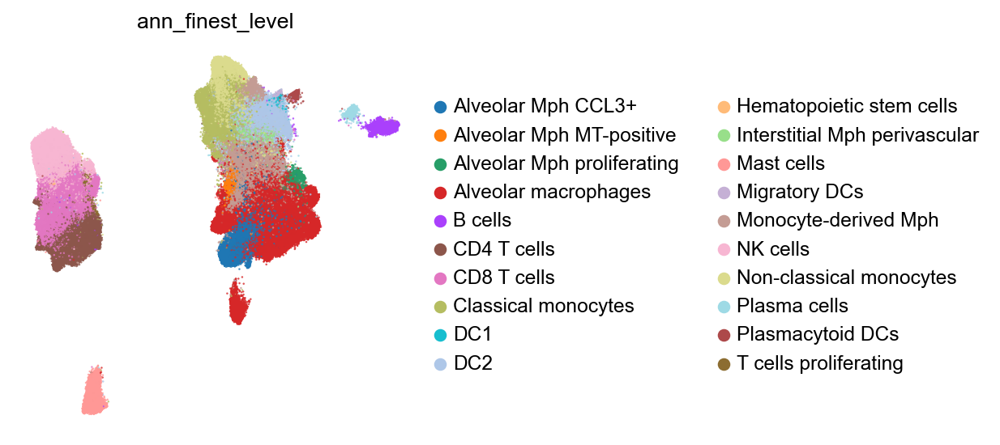

In [48]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integration1}',
    color='ann_finest_level',
    size=5,
    alpha=0.8,
    ncols=1,
)

# Metrics

In [49]:
metrics_dfs = {
    key: adata.uns[key]
    for key in adata.uns.keys()
    if key.startswith('metrics')
}

In [50]:
metrics_df = pd.concat(metrics_dfs.values())
metrics_df

,metric,metric_type,batch,label,file_id,dataset,integration_batch,integration_hyperparams,integration_label,integration_method,...,max_rss,max_vms,max_uss,max_pss,io_in,io_out,mean_load,cpu_time,integration,strategy
0,nmi,bio_conservation,dataset,ann_finest_level,integration=08c6548170--strategy=global,Immune,dataset,d8f7bfa1e2,NaN,scpoli,...,1180.35,2707.32,1116.63,1134.10,326.30,0.02,64.06,9.14,08c6548170,global
1,ari,bio_conservation,dataset,ann_finest_level,integration=08c6548170--strategy=global,Immune,dataset,d8f7bfa1e2,NaN,scpoli,...,1119.43,2525.76,1069.39,1091.36,398.29,0.02,52.92,9.35,08c6548170,global
2,cell_cycle,bio_conservation,dataset,ann_finest_level,integration=08c6548170--strategy=global,Immune,dataset,d8f7bfa1e2,NaN,scpoli,...,8952.18,12289.22,8889.69,8891.84,2524.44,0.01,39.49,15.09,08c6548170,global
3,clisi,bio_conservation,dataset,ann_finest_level,integration=08c6548170--strategy=global,Immune,dataset,d8f7bfa1e2,NaN,scpoli,...,2334.61,11938.00,2285.53,2295.68,1241.49,950.75,67.07,113.58,08c6548170,global
4,ilisi,batch_correction,dataset,ann_finest_level,integration=08c6548170--strategy=global,Immune,dataset,d8f7bfa1e2,NaN,scpoli,...,1934.22,11517.13,1865.45,1895.46,987.16,950.82,82.73,141.75,08c6548170,global
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30,M's I genes_m:NK cells,bio_conservation,dataset,ann_finest_level,integration=f4e267c962--strategy=lineage,Immune,dataset,c606b8bfe0,NaN,harmony_pytorch,...,6066.90,8922.80,6015.07,6037.07,530.43,0.02,29.96,9.92,f4e267c962,lineage
31,M's I genes_m:T cells proliferating,bio_conservation,dataset,ann_finest_level,integration=f4e267c962--strategy=lineage,Immune,dataset,c606b8bfe0,NaN,harmony_pytorch,...,6066.90,8922.80,6015.07,6037.07,530.43,0.02,29.96,9.92,f4e267c962,lineage
32,M's I genes_m:Hematopoietic stem cells,bio_conservation,dataset,ann_finest_level,integration=f4e267c962--strategy=lineage,Immune,dataset,c606b8bfe0,NaN,harmony_pytorch,...,6066.90,8922.80,6015.07,6037.07,530.43,0.02,29.96,9.92,f4e267c962,lineage
33,M's I genes_m:Neuroendocrine,bio_conservation,dataset,ann_finest_level,integration=f4e267c962--strategy=lineage,Immune,dataset,c606b8bfe0,NaN,harmony_pytorch,...,6066.90,8922.80,6015.07,6037.07,530.43,0.02,29.96,9.92,f4e267c962,lineage


In [51]:
metric_prefix = "M's I genes_m"
gene_metrics = [x for x in metrics_df['metric'].unique() if metric_prefix in x]

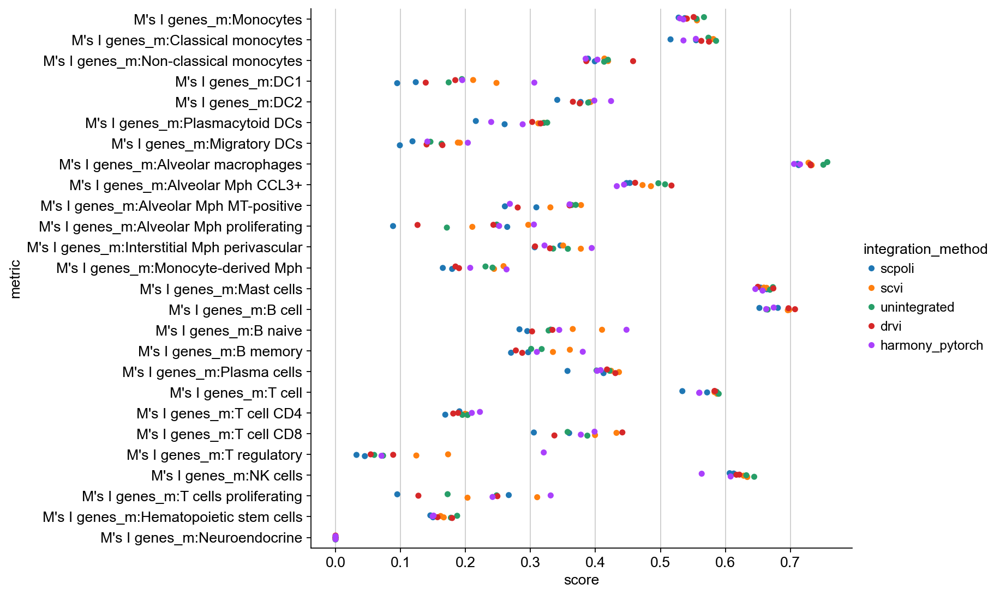

In [52]:
g = sns.catplot(
    metrics_df.query('metric.isin(@gene_metrics)'),
    x='score',
    y='metric',
    hue='integration_method',
    # palette='turbo',
    height=7,
    aspect=1.5,
)

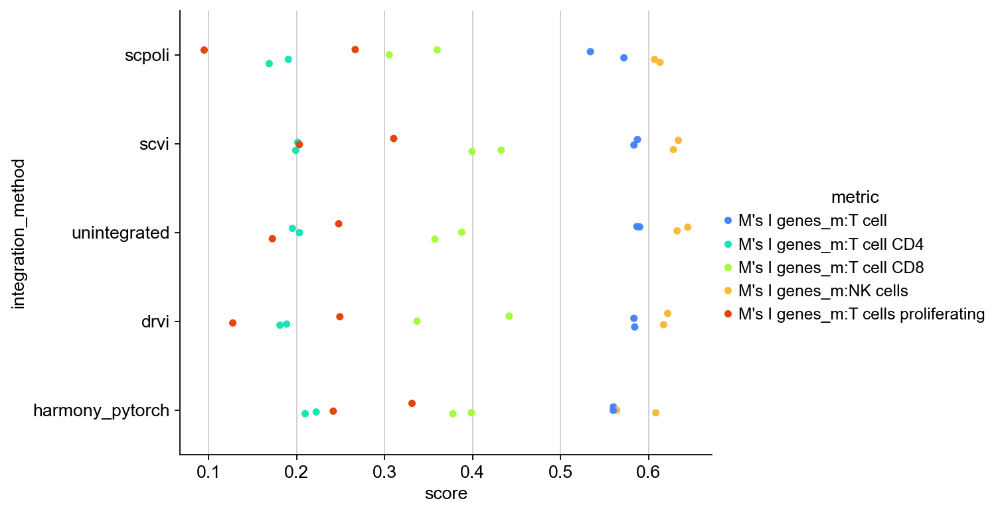

In [53]:
metric_sub = [
    "M's I genes_m:T cell",
    "M's I genes_m:T cell CD4",
    "M's I genes_m:T cell CD8",
    "M's I genes_m:NK cells",
    "M's I genes_m:T cells proliferating",
]
g = sns.catplot(
    metrics_df.query('metric.isin(@metric_sub)'),
    x='score',
    y='integration_method',
    hue='metric',
    palette='turbo',
    height=5,
    aspect=1.5,
)

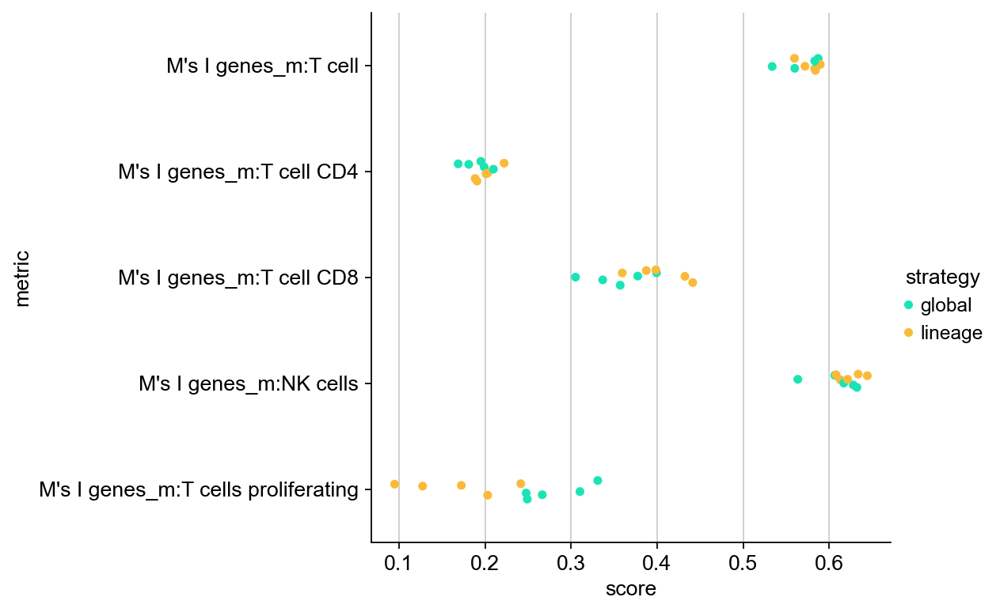

In [54]:
metric_sub = [
    "M's I genes_m:T cell",
    "M's I genes_m:T cell CD4",
    "M's I genes_m:T cell CD8",
    "M's I genes_m:NK cells",
    "M's I genes_m:T cells proliferating",
]
g = sns.catplot(
    metrics_df.query('metric.isin(@metric_sub)'),
    x='score',
    y='metric',
    hue='strategy',
    palette='turbo',
    height=5,
    aspect=1.5,
)

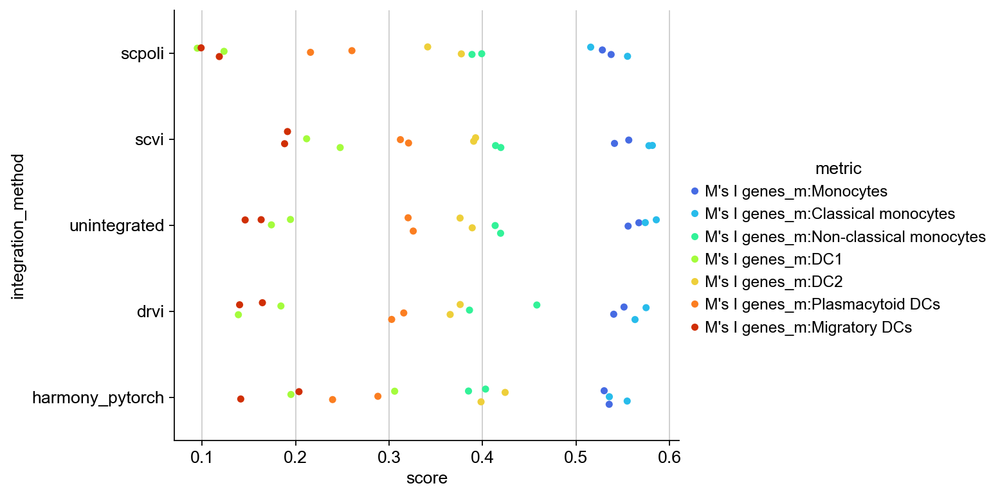

In [55]:
metric_sub = [
    "M's I genes_m:Monocytes",
    "M's I genes_m:Classical monocytes",
    "M's I genes_m:Non-classical monocytes",
    "M's I genes_m:DC1",
    "M's I genes_m:DC2",
    "M's I genes_m:Plasmacytoid DCs",
    "M's I genes_m:Migratory DCs",
]
g = sns.catplot(
    metrics_df.query('metric.isin(@metric_sub)'),
    x='score',
    y='integration_method',
    hue='metric',
    palette='turbo',
    height=5,
    aspect=1.5,
)

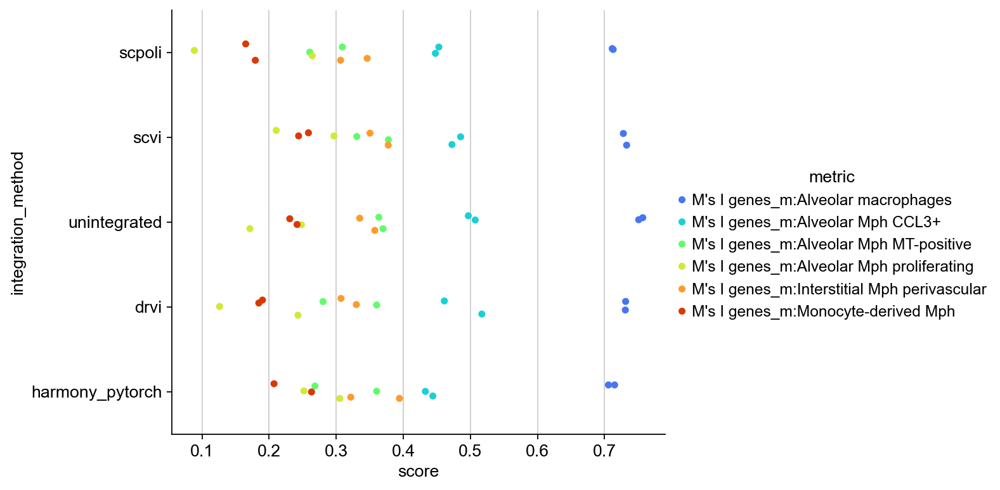

In [56]:
metric_sub = [
    "M's I genes_m:Alveolar macrophages",
    "M's I genes_m:Alveolar Mph CCL3+",
    "M's I genes_m:Alveolar Mph MT-positive",
    "M's I genes_m:Alveolar Mph proliferating",
    "M's I genes_m:Interstitial Mph perivascular",
    "M's I genes_m:Monocyte-derived Mph",
]
g = sns.catplot(
    metrics_df.query('metric.isin(@metric_sub)'),
    x='score',
    y='integration_method',
    hue='metric',
    palette='turbo',
    height=5,
    aspect=1.5,
)

In [57]:
gene_metrics

["M's I genes_m:Monocytes",
 "M's I genes_m:Classical monocytes",
 "M's I genes_m:Non-classical monocytes",
 "M's I genes_m:DC1",
 "M's I genes_m:DC2",
 "M's I genes_m:Plasmacytoid DCs",
 "M's I genes_m:Migratory DCs",
 "M's I genes_m:Alveolar macrophages",
 "M's I genes_m:Alveolar Mph CCL3+",
 "M's I genes_m:Alveolar Mph MT-positive",
 "M's I genes_m:Alveolar Mph proliferating",
 "M's I genes_m:Interstitial Mph perivascular",
 "M's I genes_m:Monocyte-derived Mph",
 "M's I genes_m:Mast cells",
 "M's I genes_m:B cell",
 "M's I genes_m:B naive",
 "M's I genes_m:B memory",
 "M's I genes_m:Plasma cells",
 "M's I genes_m:T cell",
 "M's I genes_m:T cell CD4",
 "M's I genes_m:T cell CD8",
 "M's I genes_m:T regulatory",
 "M's I genes_m:NK cells",
 "M's I genes_m:T cells proliferating",
 "M's I genes_m:Hematopoietic stem cells",
 "M's I genes_m:Neuroendocrine"]

Text(0.5, 1.05, "M's I genes_m:T regulatory")

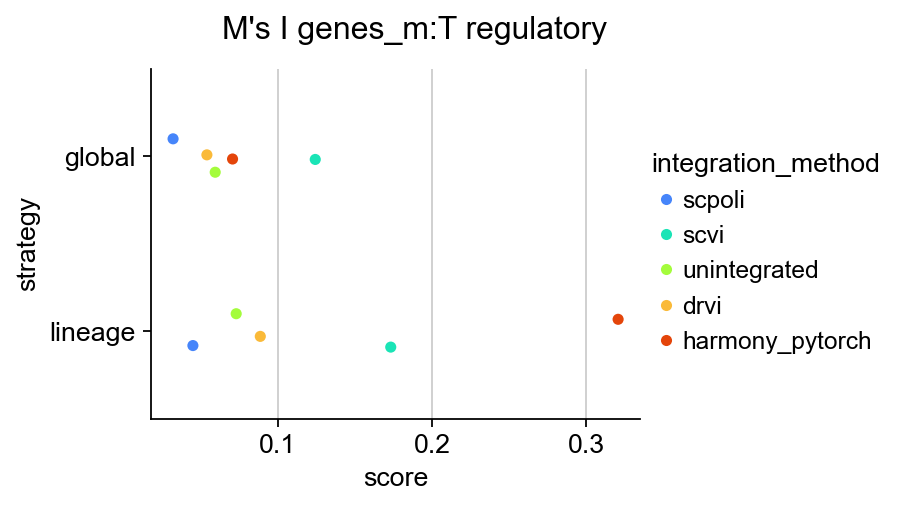

In [75]:
metric = "M's I genes_m:T regulatory"
g = sns.catplot(
    metrics_df.query('metric == @metric'),
    x='score',
    y='strategy',
    hue='integration_method',
    palette='turbo',
    height=3,
    aspect=1.5,
)
g.figure.suptitle(metric, y=1.05)

Text(0.5, 1.05, "M's I genes_m:Plasma cells")

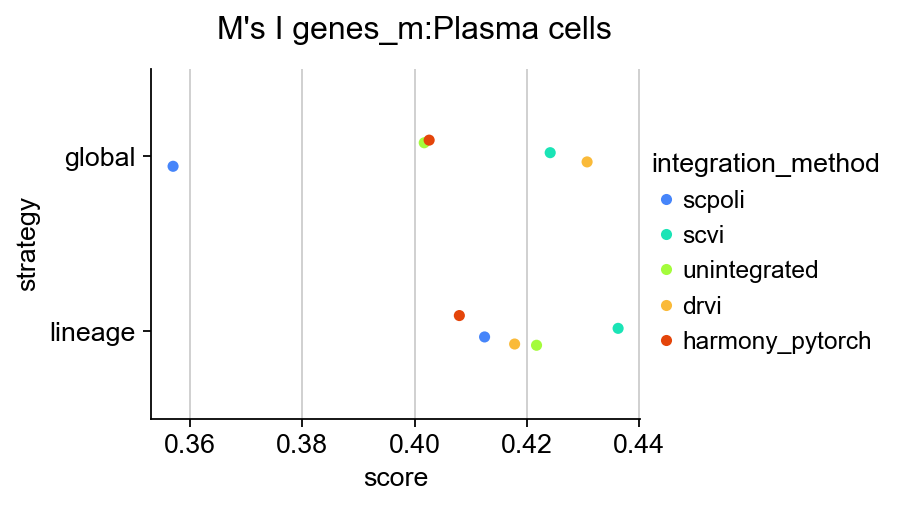

In [77]:
metric = "M's I genes_m:Plasma cells"
g = sns.catplot(
    metrics_df.query('metric == @metric'),
    x='score',
    y='strategy',
    hue='integration_method',
    palette='turbo',
    height=3,
    aspect=1.5,
)
g.figure.suptitle(metric, y=1.05)

Text(0.5, 1.05, "M's I genes_m:Hematopoietic stem cells")

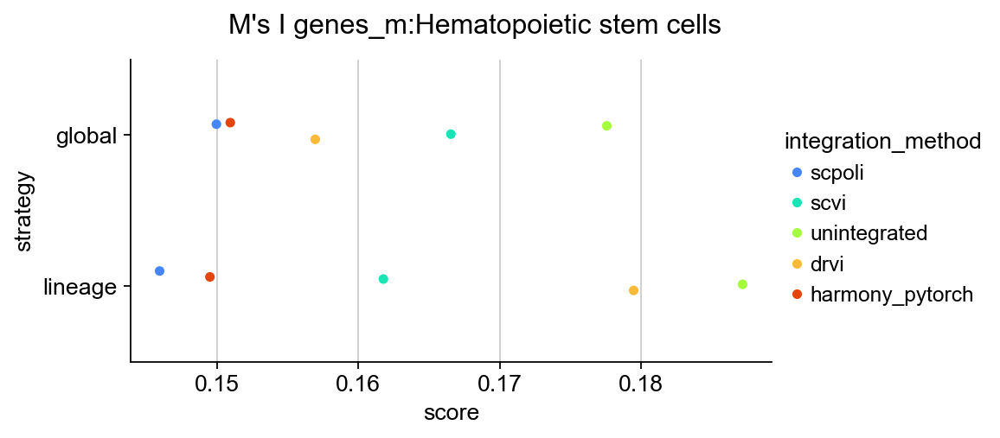

In [116]:
metric = "M's I genes_m:Hematopoietic stem cells"
g = sns.catplot(
    metrics_df.query('metric == @metric'),
    x='score',
    y='strategy',
    hue='integration_method',
    palette='turbo',
    height=3,
    aspect=2,
)
g.figure.suptitle(metric, y=1.05)